# WLASL Dual-Stream Sign Language Recognition — v9

**A CNN + Transformer pipeline for word-level ASL recognition, with a runtime path to sentence-level decoding**

This notebook implements the methodology developed for our East West University capstone
project: a dual-stream architecture that fuses **appearance features** (CNN over the
signer's frame) with **geometry features** (normalized body/hand/face landmarks), encoded
temporally with a **Transformer encoder**, and evaluated with an **accuracy-gated output
path** that only unlocks sentence-level CTC decoding once word-level accuracy clears a
threshold on validation data.

**Dataset (v8):** [ASL Citizen](https://www.microsoft.com/en-us/research/project/asl-citizen/)
(Desai et al., Microsoft Research/BU/UW/RIT 2023) — a crowdsourced isolated-sign dataset, here
restricted to its **top 2,000 classes by sample count** (of ~2,301 base-collapsed glosses),
capped at 15 videos/class/split (~30,000 videos total). Selected and cached by a separate
companion notebook, `asl_citizen_2000class_cache_builder.ipynb` — see the v8 changelog below.

> **This is v9.** v8's Kaggle session was killed by the idle timeout after Epoch 1/50 --
> a loss right at the random-guess baseline for 2,731 classes, with no checkpoint able to
> resume it and every downstream evaluation cell unrun. v9 makes no architecture changes:
> it (1) scopes the run down to the **top 1,000 classes** by sample count as a deliberate
> checkpoint before the full 2,731-class run, (2) turns on **AMP** (`CONFIG.USE_AMP`, already
> wired up but left off) to roughly halve epoch time, and (3) makes training **resumable** --
> every epoch now saves a full resume checkpoint (model/optimizer/scheduler/scaler/history),
> so re-running the training cell after a kill continues from the next epoch instead of
> starting over. Plan: 50%+ val top-1 at 1,000 classes -> widen to 1,500; otherwise iterate
> here. See the v9 changelog below for details.
>
> **This is v8.** v1–v7 spent seven versions on architecture, backbone, and regularization
> changes against the same ~4-16-videos/class WLASL pool -- and the evidence across those
> versions (see the accompanying engineering note, "Why Further Pipeline Changes Will Not
> Close the WLASL100 Gap") points at per-class data volume, not the model, as the governing
> ceiling. v8 acts on that directly: it replaces the WLASL data source entirely with **ASL
> Citizen** (21-45 videos/class -- well above WLASL's ceiling) and scales up to that dataset's
> **top 2,000 classes**, a genuine scale-up rather than a like-for-like WLASL100 swap. The model
> architecture (Sections 5, 6, 9, 10) is untouched -- this is a data-source and scale change,
> not another architecture experiment, keeping it a clean test of the data-volume hypothesis.
>
> **This is v7.** v6 swapped the appearance backbone to a Kinetics-400-pretrained `r3d_18`
> (audit Section 7.1) but the result came back **worse** than v5, not better: val top-1
> plateaued around 0.34-0.37 while train top-1 sat at 1.000 — clear overfitting, and a sign
> that a 3D backbone pretrained on whole-scene human *action* video may actively be
> mismatched with small, context-free hand crops, which is not the kind of input its filters
> were pretrained to exploit. v7 makes two changes in response, both scoped to the
> appearance pipeline: (1) per the audit's **Section 7.2**, appearance input switches from
> isolated hand crops to a **signer bounding box** (the full upper body -- head to hips,
> shoulder-to-shoulder including extended arms -- derived from pose landmarks, falling back
> to the full frame if pose detection misses), giving `r3d_18` the kind of full-scene motion
> context it was actually pretrained on; and (2) the appearance backbone's freeze depth is
> tightened (only `layer4` now trainable, was `layer2-4`) since v6's overfitting was at
> least partly a raw-capacity problem independent of input scope, and leaving it unaddressed
> would likely just reproduce the same pattern. **This change requires a full re-cache of
> the appearance data** (~8.5 hours, same order as the original full-dataset cache) since
> the crop strategy itself is changing, not just which network consumes it -- see the v7
> changelog below for the two-phase Kaggle workflow this needs. Sections 1-5 are otherwise
> unchanged from v6.

---



## Notebook Roadmap

| # | Section | Status in v7 |
|---|---|---|
| 1 | Setup & Installation | Fixed |
| 2 | Global Configuration | **Changed in v8** (data source: WLASL -> ASL Citizen; cache-dir now points at a separate cache-builder notebook's output, no more in-notebook two-phase workflow) |
| 3 | Load Dataset Annotations | **Changed in v9** (`PILOT_MODE` back on: top 1,000 classes by count, not the full 2,731; duplicate filter cell removed) |
| 4 | Dataset Exploration (EDA) | Fixed |
| 5 | MediaPipe Tasks API Visualization | Fixed |
| 6 | Dual-Stream Feature Extraction Pipeline | **Changed in v7** (hand crops -> signer bounding box) |
| 7 | Offline Feature Cache | **Handled entirely outside this notebook in v8** by `asl_citizen_2000class_cache_builder.ipynb` (~18-20h, resumable) |
| 8 | PyTorch Dataset & DataLoader | Fixed (already generic over stream count) |
| 9 | Model Architecture | **Changed in v7** (backbone freeze depth tightened; fused_dim now stream-count-aware) |
| 10 | Training Setup & Full Run | **Changed in v9** (`USE_AMP = True`; training loop now checkpoints + resumes every epoch instead of only at the end) |
| 11 | Results & Accuracy Gate Check | Fixed (TTA carried over from v5/v6) |
| 12 | Next Steps | v7-era planning, kept for history |
| 13 | Next Steps (v8) | New in v8 |


## Changelog — v2 (this version)

An independent audit of v1 (`WLASL_Notebook_Improvement_Guide.md`) identified two
independent issues to fix: a fragile environment pin, and real (if non-catastrophic)
bugs in the training pipeline. This version addresses both:

**Environment modernization (Track A):**
- Removed the `mediapipe==0.10.14` + `protobuf<5` version pin entirely. The legacy
  `mp.solutions.holistic` API it was propping up has been fully replaced with the
  actively-maintained **MediaPipe Tasks API** (`HandLandmarker`, `PoseLandmarker`,
  `FaceLandmarker`). This removes the root cause of the protobuf `ImportError`,
  rather than re-pinning around it again.

**Pipeline & training fixes (Track B):**
- Fixed a `DataLoader` crash risk: MediaPipe is not fork-safe, so on-the-fly
  extraction with `num_workers>0` would eventually crash. Resolved by adding an
  **offline feature cache** (Section 8) — extraction now runs once per video, not
  once per epoch, which also fixes the "slow" concern v1 already flagged.
- Fixed a variable-naming collision in `AppearanceStream.forward()` (`H` used for
  both "num hands" and image height on adjacent lines).
- Added gradient clipping, automatic mixed precision (AMP), a `WeightedRandomSampler`
  for class imbalance, and an aggregate hand-detection failure-rate check.
- Fixed a learning-rate scheduler bug where `CosineAnnealingLR`'s `T_max` was tied to
  the 3-epoch pilot budget and would silently break once scaled to real training.

**Deliberately not done in this pass:** the audit's Section 2.5 (splitting this
notebook into a `configs.py` / `dataset.py` / `model.py` / ... package) is sequenced
*last* in the audit's own roadmap, specifically after the fixes above are verified
working on a real Kaggle run. I've followed that ordering rather than restructuring
untested code — see the note at the end of this notebook for what I'd need from you
to do that refactor next.


## Changelog — v3 (this version)

v2 (above) fixed the environment/pipeline bugs and got a full, honest 50-epoch
run to complete without crashing. That run's own result was the real finding:
**severe overfitting**, not a remaining bug -- train_loss fell to 5.30 while
val_loss *rose* to 7.81 (above the ln(1910)&asymp;7.56 random-guessing
baseline), with best validation top-1 reaching only 0.6%. Root cause: ~7,696
training videos across up to 1,910 classes is only ~4 videos/class on average
-- plenty of room for a 12.9M-parameter model to memorize rather than
generalize.

**What changed in v3, and why:**

| Change | Where | Why |
|---|---|---|
| Appearance-stream data augmentation (random rotation &plusmn;10&deg;, brightness/contrast jitter &plusmn;15%) | `WLASLCachedDataset`, Section 8 | Directly attacks the overfitting root cause -- the model now sees varied pixels for the "same" clip every epoch instead of memorizing identical crops. One random transform per *clip* (not per frame), so the temporal motion signal isn't destroyed. Horizontal flip deliberately excluded -- sign language is handedness-sensitive. |
| Dropout raised 0.1 &rarr; 0.3 | `CONFIG`, Section 2 | Stronger regularization given how little data exists per class; complements augmentation rather than replacing it. |
| Checkpoint selection & early stopping switched from `val_top1` to `val_loss` | Section 10 | With only 2,014 val samples across ~1,910 classes, `val_top1` moves in steps of ~0.0005 per correct prediction -- too coarse to trust epoch to epoch. `val_loss` is continuous and shows real change sooner. |
| **Bug fix:** `GradScaler` state-machine break | Section 10, `run_epoch` | A diagnostic re-run of the (already-fixed-once) non-finite-gradient guard hit `RuntimeError: unscale_() has already been called on this optimizer since the last update()`. Cause: the guard called `continue` to skip a bad batch's optimizer step, but skipped `scaler.update()` along with it -- leaving the scaler's internal per-optimizer state stuck at `UNSCALED`, so the *next* batch's `unscale_()` call failed immediately. Fix: always call `scaler.step()`/`scaler.update()` every iteration; `GradScaler.step()` already has its own internal check that silently skips the actual parameter update when gradients are non-finite, so the manual skip was both redundant and the thing breaking the state machine. |

**Carried over unchanged from v2** (already fixed and confirmed working over a
full 50-epoch run): the MediaPipe timestamp-monotonicity fix, reusable
landmarkers in `build_feature_cache`, handedness-assignment-by-screen-position,
BatchNorm forced to eval mode in frozen ResNet layers, `nan_to_num` landmark
sanitization, the `isfinite`-loss batch guard, differential learning rate for
the unfrozen ResNet backbone layers (LR/10), AMP disabled (an fp16 range
overflow was the source of an earlier NaN collapse), and reloading the best
checkpoint before Section 11 evaluates the model.

**Honest expectation for this run:** augmentation and stronger regularization
should narrow the train/val gap, but with only ~4 videos/class, fully closing
it and clearing the 0.70 gate on all ~1,910 classes may not happen in one more
pass -- this is a real data-scarcity ceiling, not something code alone fixes.
If this run still falls well short, that's a legitimate, reportable finding
for the paper's limitations section, not a failure to debug further.


## Changelog — v4 (this version)

v3's run (above) showed real, if slow, learning -- val_loss fell from 7.81 to
7.25 and val_top5 climbed from 0.002 to 0.008 across 12 epochs -- but was still
far from the 0.70 gate. Comparing against the official WLASL benchmark
([dxli94/WLASL](https://github.com/dxli94/WLASL), WACV 2020) clarified why,
and suggested two concrete, low-effort changes:

**What the official benchmark showed:**
- Their best model (I3D, pretrained on **Kinetics-400** -- a video-action
  dataset, not ImageNet's static images) reaches 65.89% top-1 on **WLASL100**
  (~20 videos/class) but only 32.48% top-1 on **WLASL2000** (~10 videos/class).
- Our curated dataset averages only **~4 videos/class across ~1,910 classes**
  -- less per-class data than even their harder, lower-scoring WLASL2000 split.
- Their **Pose-TGCN** model explicitly encodes joint motion via temporal
  convolution over skeleton keypoints, rather than static per-frame
  coordinates alone.

**What changed in v4, and why:**

| Change | Where | Why |
|---|---|---|
| Restrict training to the top-100 most-represented gloss classes (`build_class_subset`) | Section 3 | Mirrors WLASL100 directly -- concentrates our existing video pool into far fewer classes, giving each class dramatically more training signal, and produces a result directly comparable to the published 65.89% top-1 ceiling. A more realistic, defensible target for this project's timeline than the full 1,910-class problem. |
| Frame-to-frame velocity features added to `GeometryStream` | Section 9 | Inspired by Pose-TGCN's explicit motion modeling. Static coordinates alone give the model no direct signal for how fast or in which direction a joint is moving -- often the most distinguishing feature between visually similar signs. Implemented as a simple first-order temporal difference concatenated with the raw coordinates, rather than a full graph-conv architecture change, to keep this change small and fast to test. |

**Deliberately not changed in v4** (flagged as future work / paper limitations
instead, given the timeline): swapping the ImageNet-pretrained ResNet-18
backbone for a Kinetics-pretrained one, and feeding full-frame/body-crop
appearance input instead of isolated hand crops. Both are the single biggest
levers in the published results, but are substantial architecture changes
better suited to a documented limitations/future-work discussion in the paper
than an implementation this close to a deadline.

**Carried over unchanged from v3:** appearance-stream augmentation, dropout
0.3, val_loss-based checkpoint selection and early stopping, the `GradScaler`
state-machine fix, differential LR for the unfrozen ResNet backbone layers,
AMP disabled, and all v1/v2 correctness fixes (MediaPipe timestamps,
handedness assignment, BatchNorm eval-mode freeze, `nan_to_num` sanitization).

**Honest expectation for this run:** with ~100x fewer classes and roughly the
same total video pool, average videos/class should rise from ~4 to something
much higher (the exact number depends on how skewed the class distribution
is -- the notebook prints it after filtering). This should meaningfully close
the gap toward the published 65.89% ceiling, though matching it exactly isn't
guaranteed given the ImageNet-vs-Kinetics pretraining gap and hand-crop-only
appearance input discussed above.


## Changelog — v5 (this version)

v4's run (above) was the first genuinely successful training result: 45.5%
validation top-1 on the 100-class subset (up from ~0.6% on the full 1,910-class
problem in v3), with val_loss stabilizing at 2.8 -- well below the ln(100)&asymp;4.61
random-guess baseline, confirming real learning rather than memorization. Still
short of the published 65.89% WLASL100 ceiling and the 0.70 gate, with a clear
remaining train/val gap (train_top1 &asymp;1.00 vs val_top1 &asymp;0.455).

Per project priorities, v5 stays within the *same* pipeline/architecture --
no backbone swap, no full-frame appearance input -- and squeezes further
accuracy from what's already built:

**What changed in v5, and why:**

| Change | Where | Why |
|---|---|---|
| Unfroze ResNet `layer2` (previously frozen through v1-v4) | `AppearanceStream`, Section 9 | The freeze was calibrated for the original ~4 videos/class reality across 1,910 classes. The v4 100-class subset gives much richer per-class data, so the backbone can likely tolerate more fine-tuning capacity without as much overfitting risk. `layer3`/`layer4` remain unfrozen as before; `conv1`/`bn1`/`layer1` remain frozen. |
| `DROPOUT` 0.3 &rarr; 0.4, `WEIGHT_DECAY` 1e-4 &rarr; 2e-4 | `CONFIG`, Section 2 | Offsets the added trainable capacity from unfreezing layer2 -- more capacity without more regularization would likely just overfit faster, not generalize better. |
| Test-time augmentation (TTA) + held-out **test set** evaluation | Section 11 | Two additions bundled together: (1) Section 11 previously only reported `val_loader` accuracy, but `val_loader` was already used for checkpoint selection/early stopping -- reporting its number as "final" is slightly optimistic. `test_loader` was never touched during training, so it's the right set for the paper. (2) TTA averages predictions across several mildly-augmented views of each test clip at inference time -- a no-retraining technique that typically recovers a couple of accuracy points by reducing sensitivity to any single crop/lighting condition. |

**Carried over unchanged from v4:** the top-100 class subset (`build_class_subset`),
`GeometryStream` velocity features, appearance-stream training augmentation,
val_loss-based checkpoint selection, the `GradScaler` fix, differential LR for
the backbone, AMP disabled, and all earlier correctness fixes.

**Honest expectation for this run:** these are incremental refinements, not a
new lever on the scale of the v4 class-subset change -- expect a modest
improvement (a few percentage points, if things go well), not another 40-point
jump. If the train/val gap doesn't narrow noticeably, that's useful information
too: it would suggest the remaining gap is more about the ImageNet-vs-Kinetics
pretraining difference (discussed in the v4 changelog) than about
regularization or backbone capacity -- in which case, further squeezing this
pipeline may be near its ceiling, and the result should be written up as-is.


## Changelog — v6 (this version)

v5's run (above) was the last iteration within the *existing* ImageNet-backbone
architecture -- unfreezing `layer2`, raising dropout/weight_decay, adding TTA and
proper held-out test-set reporting. Per the notebook's own v5 "honest expectation,"
these were incremental refinements, not a lever on the scale of v4's class-subset
change, and that expectation held: the run did **not** meaningfully close the gap
to the 0.70 gate or the published 65.89% WLASL100 ceiling. A dedicated engineering
audit (`WLASL_Pipeline_Audit_Report.md`) was then run across v1-v5 specifically to
answer *why*, and concluded the remaining gap is a **pretraining/architecture
mismatch** relative to the field's own reference benchmark -- not a hyperparameter
or regularization problem. Per that audit's Section 5, three structural properties
jointly explain the gap, none fixable by further tuning:

1. **Pretraining domain mismatch** -- our backbone is ImageNet-pretrained (static
   images, no motion); the benchmark's best model (I3D) is Kinetics-400-pretrained
   (video-action data, motion-aware from pretraining onward).
2. **Appearance input scope** -- isolated hand crops vs. the benchmark's full
   signer bounding box.
3. **Data volume per class** -- addressed already by v4's 100-class scope reduction.

Per the audit's Section 7, item 1 (**Section 7.1**) is the primary, highest-priority
recommendation and the only one made in this version:

**What changed in v6, and why:**

| Change | Where | Why |
|---|---|---|
| Appearance backbone: ImageNet-pretrained `resnet18` &rarr; Kinetics-400-pretrained `r3d_18` | `AppearanceStream`, Section 9 | Audit 7.1. `torchvision.models.video.r3d_18(weights=R3D_18_Weights.KINETICS400_V1)` is a genuine, drop-in-comparable substitute for I3D -- no external checkpoint conversion needed, unlike porting the original TensorFlow I3D weights. Where the old backbone processed every frame independently through 2D convolution and left all temporal reasoning to the Transformer afterward, `r3d_18` convolves across space *and* time directly, so motion is part of the visual features themselves, not something inferred after the fact from a stack of static per-frame embeddings. |
| `AppearanceStream.forward()` restructured for 3D input | Section 9 | 3D convolution expects `(N, C, T, H, W)`, not per-frame `(N, C, H, W)`. Each hand's full 16-frame clip is now passed through the backbone as one spatiotemporal volume (per hand, per clip) rather than 16 independent frames. `r3d_18`'s internal temporal stride (stem stride 1, then stride 2 in `layer2`/`layer3`/`layer4`) shrinks `T=16` down to `T'=2` by the final layer -- spatial dims are average-pooled away (H, W only, **not** T), and the resulting `T'=2` sequence is linearly interpolated back up to `T=16` so this stream's output shape is unchanged from v5. This keeps every downstream piece -- fusion, positional encoding, the Transformer encoder, the word head -- **completely untouched**; only `AppearanceStream` itself changes. |
| Appearance normalization stats: ImageNet mean/std &rarr; Kinetics-400 mean/std | `WLASLCachedDataset`, Section 8 | A pretrained backbone's early layers expect input normalized the same way its pretraining data was. Using ImageNet stats with a Kinetics-pretrained backbone would feed it systematically miscalibrated input. |
| Backbone freeze depth reset to `stem` + `layer1` only | `AppearanceStream`, Section 9 | v5's `layer2`-unfrozen setting was tuned for the *old* ImageNet backbone's capacity/overfitting profile on the 100-class subset. Since `r3d_18` is a different, freshly-pretrained network for this task, v6 resets to the same conservative freeze depth used in v1-v4 rather than carrying over a setting that was never validated on this backbone. `DROPOUT`/`WEIGHT_DECAY` are left at v5's values for now (0.4 / 2e-4) as a starting point -- revisit in v7 once this run's train/val gap is known. |

**No re-caching required.** The audit's Section 8 flags a ~8.5-hour re-caching
cost for the *input-scope* change (7.2, full-frame instead of hand crops) --
but that's a separate, deferred recommendation (see below). Section 7's cache
stores raw per-frame hand-crop **pixels**, not precomputed CNN features, so
swapping which network consumes those pixels at train time requires no change
to Section 6/7 at all. This is specifically why 7.1 was chosen as this version's
scoped, time-boxed change: highest expected impact, lowest engineering cost.

**Deliberately not done in v6** (per the audit's own priority ordering and this
project's fixed capstone deadline):
- **Full-frame / signer-bounding-box appearance input** (audit 7.2) -- the
  audit's second-highest-impact item, but it requires a new crop strategy in
  Section 6 *and* the ~8.5-hour full re-caching pass the audit flags explicitly
  as a cost to plan for, not discover mid-effort. Deferred to a future version
  if v6's result and remaining timeline justify it.
- **Pose-TGCN-style geometry stream** (audit 7.3) -- lowest-priority per the
  audit, since the geometry stream was never identified as the primary
  bottleneck (Section 5).

**Honest expectation for this run:** per the audit, this is the single change
most likely to meaningfully move validated accuracy, since it addresses the
root cause the audit identified rather than another regularization/capacity
tweak within the old architecture. It is not guaranteed to single-handedly
close the full 20+ point gap to 65.89% -- the audit's remaining two factors
(input scope, data volume) are still partially in play -- but per the audit's
own resource/risk framing (Section 8), if this scoped change does not
meaningfully close the gap within the project's remaining time budget, v4/v5's
45.5% top-1 result remains a valid, citable, honestly-framed capstone result.
Section 12 below carries this run's actual outcome and the resulting v7
decision.


## Changelog — v7 (this version)

**v6's actual result** (Kinetics-pretrained `r3d_18` backbone, hand crops unchanged):

```
Epoch 39/50 | train_loss=0.7925 train_top1=0.999 | val_loss=3.0179 val_top1=0.375 val_top5=0.610
```

Val top-1 plateaued in the 0.33-0.38 band for the last ~15 epochs while train top-1 sat at
~1.000 -- **worse than v5's 45.5%, not better.** This is the opposite of what the audit's
central hypothesis (pretraining/architecture mismatch) predicted, so it's worth being
precise about why before deciding what to change:

1. **This is severe overfitting, not a failure to learn** -- train_loss floors near the
   label-smoothing floor while val_loss barely moves (3.09 -> 3.02 over 15 epochs). The
   model is memorizing training clips, not generalizing.
2. **`r3d_18` has substantially more trainable capacity than `resnet18`** at the same
   freeze depth (3x3x3 kernels vs 3x3, across `layer2-4`) -- v5's "unfreeze `layer2`"
   setting was tuned for the old 2D backbone's capacity and was carried into v6 without
   re-justifying it for a 3D backbone with much more capacity per unfrozen layer.
3. **A new mismatch, likely the bigger factor: `r3d_18` was pretrained on Kinetics-400 --
   whole-scene, whole-body human *action* video.** Its 3D filters are tuned to exploit
   spatial context and motion across a full scene. Feeding it small, isolated 112x112 hand
   crops may deny it exactly the signal its filters are specialized to use, and the crops
   are also fairly repetitive frame-to-frame for a fixed hand-tracking box -- easy to
   memorize, low in the motion/context signal a video backbone actually wants.

Per the audit's own priority ordering, **Section 7.2** (full-frame / signer bounding box
appearance input) is the next-highest-impact lever after 7.1, and directly targets factor 3
above. v7 makes two changes together:

| Change | Where | Why |
|---|---|---|
| Appearance input: isolated hand crops (2 slots) -> single **signer bounding box** crop (1 slot) | Section 6 (`get_signer_bbox`, `crop_signer`, `extract_dual_stream_features`) | Audit 7.2. The signer bbox spans head-to-hips and shoulder-to-shoulder including extended arms, derived from pose landmarks (falling back to the full frame if pose detection misses that frame) -- the kind of full-scene content `r3d_18` was actually pretrained to exploit, unlike a small tracked hand patch. |
| `CONFIG.NUM_APPEARANCE_STREAMS`: 2 -> 1 | Section 2, wired into `AppearanceStream`'s output reshape and `DualStreamSLRModel.fused_dim` | One signer crop per frame now, not one crop per hand. `AppearanceStream.forward()` itself needed no change -- it was already generic over stream count -- only the fixed `* 2` in `fused_dim` was hardcoded and needed to read this constant instead. |
| Backbone freeze depth: `layer2-4` trainable -> **only `layer4`** trainable | `AppearanceStream`, Section 9 | Directly addresses factor 2 above -- v6's freeze depth was inherited from the old 2D backbone's capacity profile without being re-justified for `r3d_18`. Freezing through `layer3` keeps nearly all of the Kinetics-pretrained representation intact and lets only the final block adapt to this task, a standard small-dataset transfer-learning choice. |
| `DROPOUT`: 0.4 -> 0.5, `WEIGHT_DECAY`: 2e-4 -> 3e-4 | Section 2 (`CONFIG`) | Additional regularization pressure alongside the freeze-depth change, given how fast v6 reached train_top1=1.0. |

**This requires a full re-cache** (~8.5h, same order as the original full-dataset cache) --
unlike v6's backbone swap, the *crop strategy itself* is changing, so the existing cache's
raw pixels (hand crops) can't be reused. Section 2 now supports a two-phase workflow for
this, mirroring how the original cache was built:

- **Phase 1 (build):** `CONFIG.BUILDING_V7_CACHE = True` routes `CACHE_DIR` to a writable
  `/kaggle/working` path; run through Section 7 only (Save & Run All), then stop.
- **Phase 2 (train):** after adding Phase 1's output as a new Kaggle input dataset, set
  `BUILDING_V7_CACHE = False` and update `CACHE_DIR_V7_MOUNTED` to the new mounted path,
  then run the full notebook.

**Honest expectation for this run:** the combination of full-scene input (matching what
`r3d_18` expects) and tighter regularization (addressing the overfitting v6 showed
directly) is a reasonable bet, but v6's result is a real data point against assuming the
audit's root-cause ranking transfers cleanly to this dataset's scale (100 classes, small
per-class sample counts). If v7 doesn't clear v5's 45.5% either, that's meaningful signal
that the backbone-pretraining-mismatch story isn't the dominant factor at this dataset
size, and v4/v5's result should likely be the one reported. Section 12 carries this run's
actual outcome and the v8 decision.


## Changelog — v8 (this version)

**v1-v7's own evidence closed the question of whether further pipeline tuning would help:**
the only change that produced a large, unambiguous improvement across the whole project was
v4's move to a 100-class subset -- concentrating the same fixed, ~4-16-videos-per-class video
pool into far fewer classes. v5 (more capacity/regularization/TTA) and v6 (a substantially
stronger Kinetics-pretrained 3D backbone) both held the data fixed and varied the model -- v6
in particular *regressed* despite being the single most aggressive architecture change in the
project, which is itself informative: bigger capacity overfits faster on ~10-16 examples/class,
exactly as bias-variance theory predicts, and no amount of augmentation or pretraining
manufactures a new signer, camera angle, or signing speed for a class that only has a handful
of clips to begin with (full reasoning in the accompanying engineering note, "Why Further
Pipeline Changes Will Not Close the WLASL100 Gap").

That note's own conclusion named the two real fixes as (1) sourcing more video per class, or
(2) reframing as few-shot/metric learning -- and flagged (1) as outside this project's
remaining timeline for lack of a ready alternative dataset. That constraint no longer holds:
**ASL Citizen** (Microsoft Research/BU/UW/RIT, Desai et al. 2023) is a crowdsourced isolated-
sign dataset whose own per-class counts (min 21 / median 31 / max 45) comfortably clear the
ceiling our WLASL rebuild was stuck under. v8 acts on lever (1) directly, and does it at a
larger scale than a like-for-like WLASL100 swap:

| Change | Where | Why |
|---|---|---|
| Data source: WLASL curated dataset -> **ASL Citizen** | Section 2 (`CONFIG`), Section 3 | Directly targets the data-volume ceiling v1-v7 diagnosed, rather than another architecture change against the same starved pool. |
| Scope: not a 100-class like-for-like swap -- the **top 2,000** ASL Citizen classes by sample count | Section 3 (selection happens upstream, in the separate cache-builder notebook) | A deliberate scale-up (BSc capstone scope), not just a bottleneck fix: classifying across 2,000 classes with solid per-class data is a substantially bigger contribution than replicating the WLASL100 benchmark on a healthier dataset. No WLASL vocabulary matching is involved -- classes are selected purely by ASL Citizen's own sample counts. |
| `NUM_CLASSES`: 100 -> ~2,000 | Section 3 (now driven entirely by `class_list_asl_citizen.txt`'s length) | Follows directly from the scope change above; the model's output layer resizes automatically since `NUM_CLASSES` is read from `class_list`, not hardcoded. |
| Caching moved to a **separate notebook** (`asl_citizen_2000class_cache_builder.ipynb`) | Section 2, Section 7 | At this scale (~30k videos vs. v7's ~11.7k), caching alone is an ~18-20h job -- too long to interleave with this notebook's old Phase 1/Phase 2 pattern. The cache-builder notebook handles class selection, per-class capping, and feature extraction independently; this notebook now only ever reads an already-built, mounted cache. |
| `build_class_subset()` / `SUBSET_TOP_K` (Section 3, v4-v7) | Removed | Class selection (top-2,000-by-count, per-class cap) now happens upstream in the cache-builder notebook, so `nslt_data`/`class_list` arrive pre-filtered here. |
| `FULL_METADATA` (`WLASL_custom_split.json`) | Removed from `CONFIG` | ASL Citizen has no equivalent file, and nothing downstream actually depended on its contents -- bbox/signer-id data was never read by feature extraction (confirmed while designing the cache-builder notebook). |

**What does NOT change:** Sections 5, 6, 9, and 10 (MediaPipe setup, signer-bbox appearance
extraction, the dual-stream model architecture, and the training loop) are untouched -- v8 is
a data-source and scale change, not an architecture change, which keeps this a clean test of
the data-volume hypothesis rather than another confound.

**Honest expectation for this run:** absolute accuracy is not directly comparable to v4/v5's
45.5% or the published WLASL100 65.89% benchmark -- those are 100-way problems; this is a
2,000-way problem on a different dataset entirely. A meaningful result here is **top-1/top-5
accuracy at a scale an order of magnitude larger than anything v1-v7 attempted, backed by a
per-class sample count that no longer bottlenecks the model** -- the right comparison is
against how a 2,000-way classifier trained on WLASL's own starved per-class counts would be
expected to perform (very poorly, given v1-v3's ~0.6% result on the *full 1,910-class* WLASL
problem), not against the 100-class benchmark number. Section 13 (new, at the end) carries
this run's actual outcome and what v9 should address.

**Before running:** the companion cache-builder notebook must be run first, and its two
outputs added as Kaggle input datasets -- the `.npz` cache folder and the `manifest` folder
(`nslt_asl_citizen.json` + `class_list_asl_citizen.txt`). Update `CONFIG.CACHE_DIR` and
`CONFIG.MANIFEST_DIR` in Section 2 to match your actual mounted paths.

## Changelog — v9 (this version)

**What happened to v8:** the Kaggle session was killed (idle timeout) after exactly
**Epoch 1/50** -- `train_loss=7.93 / val_loss=8.27`, both ~= `ln(2731)`, i.e. the loss a
completely untrained 2,731-way classifier starts at. Every cell after the training loop
(results plot, accuracy-gate check, sample predictions, TTA test eval) never ran. So v8's
"accuracy is nothing" wasn't evidence the model can't learn at this scale -- it was one
epoch of an interrupted run, with no checkpoint capable of resuming it.

**v9 makes three changes, none of them architecture changes:**

| Change | Where | Why |
|---|---|---|
| `PILOT_MODE = True`, top **1,000** classes (not the full 2,731) | Section 3 | A deliberate scale-down before committing to the full run: 1,000 classes is still 10x v4/v5's 100-class benchmark, but should train faster and is a fairer first checkpoint than jumping straight to 2,731. Plan: if this clears 50%+ val top-1, widen to 1,500 next; if not, iterate at 1,000 rather than scaling up further. |
| Removed a duplicate pilot-mode cell (old Section 3 had the identical restriction logic in two back-to-back cells) | Section 3 | Was harmless as two no-ops in v8 (`PILOT_MODE = False` in both), but re-running real filtering logic twice back-to-back the moment `PILOT_MODE = True` is just confusing to read -- one is enough. |
| `CONFIG.USE_AMP`: `False` -> `True` | Section 2 (`CONFIG`) | Autocast + `GradScaler` calls were already wired up (unused while `False`) -- this alone should roughly halve epoch time on a Kaggle T4/P100 with no real accuracy cost. Matters more now that a run needs to survive multiple sessions. |
| **Resumable training**: every epoch now saves a full resume checkpoint (`last_model.pt`: model + optimizer + scheduler + scaler + `history` + early-stopping counters), and the training cell reloads it automatically if present | Section 10 | This is the actual fix for what killed v8 -- previously only the best-val_loss checkpoint was saved, and `history` only hit disk once, at the very end, so a mid-run kill lost everything. Now re-running the training cell after a kill continues from the next epoch instead of restarting at epoch 1. `training_history.json` is also now written after every epoch, not just at the end. |

**Important caveat on resuming:** this survives an idle-kill + reopen **within the same
edit session**, since Kaggle's `/kaggle/working` persists across that. If you instead start
a brand-new committed version of this notebook, `/kaggle/working` resets -- add the previous
version's output as an input dataset and copy its `checkpoints/` folder into
`CONFIG.CHECKPOINT_DIR` before running the training cell, or the run will (correctly) detect
no checkpoint and start fresh.

**Nothing else changed:** Sections 5, 6, 9 (MediaPipe setup, signer-bbox appearance
extraction, dual-stream model architecture) are untouched. This keeps v9 a clean test of
whether the model can learn at 1,000-class scale given a run that's actually allowed to
finish, rather than confounding that question with an architecture change.

---

### v9.1 patch (same version, applied after the first 1,000-class attempt)

The first v9 run showed the loss essentially flat at `ln(1000)=6.91` through epoch 7, and
by epoch 7 `run_epoch`'s non-finite-loss guard started firing repeatedly (`logits_abs_max=nan`
with finite inputs) -- meaning some of the model's weights had already gone permanently NaN,
not just one bad gradient step. Three changes in response, all precautionary / defensive
rather than architecture changes:

- `CONFIG.USE_AMP`: reverted `True` -> `False`. fp16's smaller dynamic range than fp32 is a
  plausible contributor to the overflow, on top of fresh (non-pretrained) Transformer/fusion
  layers training at a real LR. Isolating this to get one stable baseline before treating AMP
  as its own separate experiment.
- `CONFIG.LR`: `3e-4` -> `1e-4`, `CONFIG.GRAD_CLIP_NORM`: `1.0` -> `0.5`. Extra precaution
  alongside disabling AMP.
- **NaN rollback guard, Section 10:** the training loop now checks `model_has_nan(model)`
  after every epoch. If weights have gone NaN, it stops immediately *without* saving that
  epoch to `last_model.pt` (so a future resume can't inherit a dead model) and leaves
  `best_model.pt` -- the last epoch that actually improved val_loss -- as the safe resume
  point. The resume block at the top of Section 10 also now checks the loaded
  `last_model.pt` for NaN before trusting it, and falls back to `best_model.pt` automatically
  (resetting optimizer/scheduler state, since it no longer matches) if it finds one.


## 1. Setup & Installation

Per the audit: the previous pin (`mediapipe==0.10.14` + `protobuf<5`) existed only to
keep the deprecated `solutions.holistic` API alive, and was fighting Kaggle's rolling
base-image updates every time protobuf/TensorFlow shifted underneath it. We install
current, unpinned packages instead, and use the actively-maintained
**MediaPipe Tasks API** throughout (`HandLandmarker`, `PoseLandmarker`,
`FaceLandmarker`) rather than `mp.solutions.holistic`. This removes the conflict at
its root instead of patching around it.

The Tasks API loads pretrained model *bundles* (`.task` files) from Google's model
storage rather than bundling them in the pip package, so we download those once
below too.


In [1]:
!pip install -q -U mediapipe opencv-python-headless einops


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 83.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 8.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [2]:
# Download the MediaPipe Tasks model bundles we need: hand, pose, and a reduced
# face-landmark model (for the non-manual grammatical markers -- brow/mouth --
# per methodology Stage 1). These are cached in /kaggle/working and only need to
# download once per session.
!wget -q -O hand_landmarker.task https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task
!wget -q -O pose_landmarker_lite.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task
!wget -q -O face_landmarker.task https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task

import os
for f in ["hand_landmarker.task", "pose_landmarker_lite.task", "face_landmarker.task"]:
    size_mb = os.path.getsize(f) / 1e6 if os.path.exists(f) else 0
    print(f"{f}: {'OK' if size_mb > 0.1 else 'MISSING/EMPTY'} ({size_mb:.1f} MB)")


hand_landmarker.task: OK (7.8 MB)
pose_landmarker_lite.task: OK (5.8 MB)
face_landmarker.task: OK (3.8 MB)


## Imports

In [3]:
import os
import json
import random
import math
import types
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision
# v6: swapped ImageNet resnet18 for a Kinetics-400-pretrained 3D backbone
# (audit Section 7.1) -- see AppearanceStream in Section 9.
from torchvision.models.video import r3d_18, R3D_18_Weights

import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision

print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MediaPipe:", mp.__version__)
print("CUDA available:", torch.cuda.is_available())


Torch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
MediaPipe: 0.10.35
CUDA available: True


## 2. Global Configuration

Every path, hyperparameter, and architectural switch lives here. When we iterate in
later versions, this cell is the single place to change — nothing below should have
hardcoded values that duplicate what's defined here.

`ENABLE_SENTENCE_LEVEL` is the runtime flag from our methodology's accuracy-gated
design: it stays `False` until word-level validation accuracy clears
`ACCURACY_GATE_THRESHOLD`, at which point the (currently stubbed) CTC decoder path
can be switched on without changing the model's architecture.

Per the audit's Appendix (consolidated `CONFIG` diff), this version adds
`GRAD_CLIP_NORM`, `USE_AMP`, and a proper `EPOCHS_FULL` separate from
`EPOCHS_PILOT` — see Section 10 for why the pilot/full split matters for the LR
scheduler.


In [4]:
class CONFIG:
    # ---- v8: data source switch -- WLASL curated dataset -> ASL Citizen ----
    # v1-v7 diagnosed the remaining accuracy gap as a per-class data-volume
    # ceiling (our WLASL rebuild: median 6, max 16 videos/class -- even the
    # top-100 subset couldn't exceed that). ASL Citizen's own per-class counts
    # (min 21 / median 31 / max 45) are well above that ceiling, so v8 swaps
    # the entire data source rather than tuning the model further against the
    # same starved pool (see v8 changelog above).
    #
    # Caching now happens in a SEPARATE notebook
    # (asl_citizen_2000class_cache_builder.ipynb) rather than a Phase 1/Phase 2
    # split inside this one -- run that notebook first, add its two outputs
    # (the .npz cache folder AND the manifest folder) as Kaggle input datasets,
    # then update the two paths below to match.
    WORK_DIR = Path("/kaggle/working")

    # UPDATE to match wherever the cache-builder notebook's manifest output
    # (nslt_asl_citizen.json + class_list_asl_citizen.txt) got mounted.
    MANIFEST_DIR = Path("/kaggle/input/datasets/nadimsrabon6/asl-citizen-cache-manifest/manifest")
    NSLT_JSON = MANIFEST_DIR / "nslt_asl_citizen.json"
    CLASS_LIST = MANIFEST_DIR / "class_list_asl_citizen.txt"

    # v8.1: caching was split across 3 Kaggle accounts to get around the
    # per-account output quota on 63k videos. Rather than merging the three
    # .npz outputs into one dataset (which just re-triggers the same quota
    # problem), all three are mounted as separate read-only input datasets
    # and the Dataset class below looks a video up across all of them.
    # UPDATE each path to match wherever that account's cache-builder output
    # got mounted (check with `!ls /kaggle/input/`).
    CACHE_DIRS = [
        Path("/kaggle/input/notebooks/aniruddha2022/asl-shared-cache-building-id00/feature_cache_shard_0"),
        Path("/kaggle/input/notebooks/redoanmozumder/asl-shared-cache-building-id02/feature_cache_shard_2"),
        Path("/kaggle/input/notebooks/pranaysahaps/asl-shared-cache-building-id01/feature_cache_shard_1"),
    ]

    # ASL Citizen's own videos -- NOT read during training (the Dataset class
    # in Section 8 reads only from the cache shards' .npz files); kept here
    # only for reference/debugging.
    VIDEOS_DIR = Path("/kaggle/input/datasets/pranaysahaps/asl-citizen/videos")

    # v1-v7 WLASL cache -- kept only for reference/rollback, not read once v8's
    # ASL Citizen paths above are active.
    CACHE_DIR_V7_WLASL = Path("/kaggle/input/datasets/nadimsrabon6/cache-results-v7/feature_cache_v7_fullframe")

    # New: separate WRITABLE location for model checkpoints -- cache shards are
    # read-only now, so checkpoints can't be saved there.
    CHECKPOINT_DIR = WORK_DIR / "checkpoints"

    # ---- MediaPipe Tasks API model bundles (downloaded in Section 1) ----
    HAND_MODEL_PATH = "hand_landmarker.task"
    POSE_MODEL_PATH = "pose_landmarker_lite.task"
    FACE_MODEL_PATH = "face_landmarker.task"

    # ---- Reproducibility ----
    SEED = 42

    # ---- Video / temporal sampling ----
    FRAME_COUNT = 16          # T=16 frames per clip, per methodology Stage 4
    IMG_SIZE = 112            # v7: signer-bbox crop size fed to the CNN
                                # stream (was hand-patch crop size in v1-v6);
                                # unchanged value -- still matches r3d_18's
                                # Kinetics-400 pretraining crop size.
    RAW_RESIZE = (640, 480)   # capture resolution assumed by the methodology doc

    # ---- Appearance stream ----
    # v7: one signer-bbox crop per frame, replacing v1-v6's two hand-crop
    # slots -- wired into AppearanceStream's output reshape and
    # DualStreamSLRModel's fused_dim (Section 9).
    NUM_APPEARANCE_STREAMS = 1
    SIGNER_BBOX_MARGIN = 0.25  # padding around the pose-derived signer box

    # ---- Landmark stream ----
    N_HAND_LANDMARKS = 21
    N_POSE_LANDMARKS = 33
    N_FACE_LANDMARKS = 10     # reduced brow/mouth subset (non-manual markers)

    # ---- Model dimensions ----
    CNN_EMBED_DIM = 256
    LANDMARK_EMBED_DIM = 128
    D_MODEL = 256
    N_HEADS = 4
    N_ENCODER_LAYERS = 3
    FFN_DIM = 512
    DROPOUT = 0.5          # v7: raised from 0.4 -- v6's r3d_18 run reached
                            # train_top1=1.00 within ~20 epochs while val_top1
                            # plateaued at 0.34-0.37, worse overfitting than v5
                            # ever showed. Raised alongside tightening the
                            # backbone freeze depth (Section 9) rather than
                            # relying on either fix alone.

    # ---- Training ----
    BATCH_SIZE = 8
    NUM_WORKERS = 2
    # v9.1: lowered from 3e-4 -- alongside disabling AMP and tightening grad
    # clipping, one more precaution against the overflow that produced NaN
    # logits in the v9 1,000-class run. Fresh (non-pretrained) Transformer +
    # fusion + word_head layers are the ones actually training fast here
    # (backbone gets LR/10 regardless), so this is the lever most likely to
    # matter.
    LR = 1e-4
    WEIGHT_DECAY = 3e-4    # v7: raised from 2e-4 alongside the dropout increase --
                            # same overfitting evidence from v6's run, additional
                            # regularization pressure on top of the tightened
                            # freeze depth (Section 9).
    EPOCHS_PILOT = 3          # sanity-check run only -- confirms the loop runs

    # Bumped from 30 -- with ~1,910 classes and this dataset size, 30 epochs
    # risks stopping before the model has meaningfully separated classes.
    # Early stopping below means this is a ceiling, not a commitment to run
    # the full 50 -- it'll stop earlier if val accuracy plateaus.
    EPOCHS_FULL = 50

    # New: early stopping -- stop if val_top1 hasn't improved in this many
    # epochs, so a plateaued run doesn't burn the rest of the 12-hour budget.
    EARLY_STOPPING_PATIENCE = 15

    LABEL_SMOOTHING = 0.1

    # ---- Track B additions: training hygiene (audit Section 3.2) ----
    # v9.1: tightened from 1.0 -- the 1,000-class run hit escalating NaN
    # logits by epoch 7 (weights had already gone NaN, not just one bad
    # gradient step), so clipping harder as one precaution alongside
    # disabling AMP below and adding the NaN rollback guard in Section 10.
    GRAD_CLIP_NORM = 0.5
    # v9.1: reverted to False -- v9 turned this on for speed, but the same
    # run then went unstable (NaN logits, escalating epoch over epoch).
    # fp16's much smaller dynamic range than fp32 is a likely contributor on
    # top of fresh (non-pretrained) Transformer/fusion layers at this LR --
    # isolating it here to get one stable baseline before re-enabling AMP as
    # its own separate experiment.
    USE_AMP = False

    # ---- Accuracy-gated output path (methodology Stage 5) ----
    ACCURACY_GATE_THRESHOLD = 0.70
    ENABLE_SENTENCE_LEVEL = False

    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(CONFIG.SEED)

# v8.1: caching is fully external and now split across 3 shards (see
# asl_citizen_2000class_cache_builder.ipynb x3), so this notebook only ever
# reads from already-built, mounted cache shards -- no Phase 1/Phase 2 split
# here, and no merge step that would re-hit the output quota.
CACHE_INDEX = {}
for shard_dir in CONFIG.CACHE_DIRS:
    assert shard_dir.exists(), (
        f"Cache shard not found at {shard_dir} -- confirm you've added that "
        f"account's cache-builder output as an input dataset via 'Add Data' "
        f"and updated CACHE_DIRS above to the exact mounted path "
        f"(check with `!ls /kaggle/input/`)."
    )
    shard_files = list(shard_dir.glob("*.npz"))
    dupes = [f.stem for f in shard_files if f.stem in CACHE_INDEX]
    if dupes:
        print(f"WARNING: {len(dupes)} video(s) in {shard_dir} already indexed "
              f"from a previous shard -- shards may overlap. First few: {dupes[:5]}")
    for f in shard_files:
        CACHE_INDEX[f.stem] = f
    print(f"  {shard_dir}: {len(shard_files)} npz files")

print(f"Found {len(CACHE_INDEX)} total unique cached .npz files across "
      f"{len(CONFIG.CACHE_DIRS)} shards")

import csv
import json
from pathlib import Path

# v8.1: the manifest (nslt_asl_citizen.json + class_list_asl_citizen.txt)
# was never produced by a separate cache-builder notebook -- the 3 caching
# notebooks read straight from ASL Citizen's own splits/*.csv and cached
# whichever videos they were assigned, with no manifest as an output.
# This cell builds the manifest directly from those CSVs, right here,
# filtered down to only videos that actually finished caching (present in
# CACHE_INDEX) -- since 63,550 cached out of a larger raw total means plenty
# of CSV rows won't have a matching .npz.

SPLITS_DIR = Path("/kaggle/input/datasets/pranaysahaps/asl-citizen/splits")
SPLIT_FILES = {
    "train": SPLITS_DIR / "train.csv",
    "val": SPLITS_DIR / "val.csv",
    "test": SPLITS_DIR / "test.csv",
}

# --- Pass 1: collect every (video_id, gloss, subset) row that's cached ---
rows = []
all_glosses = set()
for subset, csv_path in SPLIT_FILES.items():
    assert csv_path.exists(), f"Missing split file: {csv_path}"
    with open(csv_path, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            video_id = Path(row["Video file"]).stem
            gloss = row["Gloss"]
            all_glosses.add(gloss)
            if video_id in CACHE_INDEX:
                rows.append((video_id, gloss, subset))

print(f"Total CSV rows across splits: matched {len(rows)} against CACHE_INDEX "
      f"(out of {sum(1 for _ in open(SPLIT_FILES['train'])) + sum(1 for _ in open(SPLIT_FILES['val'])) + sum(1 for _ in open(SPLIT_FILES['test'])) - 3} raw rows)")

# --- class_list_asl_citizen.txt: sorted unique glosses -> fixed index order ---
class_list = sorted(all_glosses)
class_to_idx = {g: i for i, g in enumerate(class_list)}
print(f"Num classes (full ASL Citizen vocab): {len(class_list)}")

# --- nslt_asl_citizen.json: {video_id: {"action": [class_idx, 0, 0], "subset": subset}} ---
# start/end frame indices (positions 1, 2 of "action") are never read anywhere
# in Section 8's __getitem__ -- only action[0] is -- so 0, 0 is a safe dummy.
nslt_data = {}
subset_counts = Counter()
for video_id, gloss, subset in rows:
    nslt_data[video_id] = {
        "action": [class_to_idx[gloss], 0, 0],
        "subset": subset,
    }
    subset_counts[subset] += 1

print(f"Manifest entries by subset: {dict(subset_counts)}")

# --- Write both files to CONFIG.MANIFEST_DIR (writable location, since the
# original read-only mount was never actually populated) ---
CONFIG.MANIFEST_DIR = CONFIG.WORK_DIR / "manifest"
CONFIG.MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
CONFIG.NSLT_JSON = CONFIG.MANIFEST_DIR / "nslt_asl_citizen.json"
CONFIG.CLASS_LIST = CONFIG.MANIFEST_DIR / "class_list_asl_citizen.txt"

with open(CONFIG.NSLT_JSON, "w") as f:
    json.dump(nslt_data, f)

with open(CONFIG.CLASS_LIST, "w") as f:
    for idx, gloss in enumerate(class_list):
        f.write(f"{idx}\t{gloss}\n")

print(f"Wrote manifest to {CONFIG.MANIFEST_DIR}")
print(f"  {CONFIG.NSLT_JSON.name}: {len(nslt_data)} entries")
print(f"  {CONFIG.CLASS_LIST.name}: {len(class_list)} classes")

assert CONFIG.NSLT_JSON.exists() and CONFIG.CLASS_LIST.exists()

# CHECKPOINT_DIR is writable (/kaggle/working), so this mkdir is fine.
CONFIG.CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Device: {CONFIG.DEVICE}")

  /kaggle/input/notebooks/aniruddha2022/asl-shared-cache-building-id00/feature_cache_shard_0: 21183 npz files
  /kaggle/input/notebooks/redoanmozumder/asl-shared-cache-building-id02/feature_cache_shard_2: 21184 npz files
  /kaggle/input/notebooks/pranaysahaps/asl-shared-cache-building-id01/feature_cache_shard_1: 21183 npz files
Found 63550 total unique cached .npz files across 3 shards
Total CSV rows across splits: matched 63550 against CACHE_INDEX (out of 83399 raw rows)
Num classes (full ASL Citizen vocab): 2731
Manifest entries by subset: {'train': 29175, 'val': 9192, 'test': 25183}
Wrote manifest to /kaggle/working/manifest
  nslt_asl_citizen.json: 63550 entries
  class_list_asl_citizen.txt: 2731 classes
Device: cuda


## 3. Load Dataset Annotations

We load the three annotation files produced during dataset curation:

- **`nslt_custom.json`** — flat `video_id -> {subset, action: [class_index, start, end]}`.
  This is our primary source of truth for splits and labels.
- **`custom_class_list.txt`** — `class_index -> gloss` mapping (typo-corrected).
- **`WLASL_custom_split.json`** — full per-instance metadata (bbox, signer_id, source
  url), used only when we need more than a label.

Every class in this dataset is guaranteed at least one train, val, and test example —
see the dataset's dataset preparation report for exactly how that was verified.


In [5]:
with open(CONFIG.NSLT_JSON, "r") as f:
    nslt_data = json.load(f)

class_list = {}
with open(CONFIG.CLASS_LIST, "r") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        idx_str, gloss = line.split("\t", 1)
        class_list[int(idx_str)] = gloss

NUM_CLASSES = len(class_list)
print(f"Videos in nslt_asl_citizen.json: {len(nslt_data)}")
print(f"Classes in class_list_asl_citizen.txt: {NUM_CLASSES}")

# v8: no top-K subset filter needed here anymore -- the cache-builder notebook
# already selected the top 2,000 ASL Citizen classes by sample count and
# capped each at MAX_PER_CLASS before caching, so nslt_data/class_list arrive
# pre-filtered. (v1-v7's build_class_subset()/SUBSET_TOP_K step, previously
# run here against the WLASL curated dataset, has moved upstream into the
# separate cache-builder notebook's Section 4.) FULL_METADATA is also gone --
# ASL Citizen has no equivalent file, and nothing downstream ever read it.

# Quick peek at a few entries
sample_ids = list(nslt_data.keys())[:5]
pd.DataFrame([
    {"video_id": vid, **nslt_data[vid], "gloss": class_list[nslt_data[vid]["action"][0]]}
    for vid in sample_ids
])


Videos in nslt_asl_citizen.json: 63550
Classes in class_list_asl_citizen.txt: 2731


,video_id,action,subset,gloss
0,35618482303951104-IMPOSSIBLE,"[1218, 0, 0]",train,IMPOSSIBLE
1,6958143575951994-PARK,"[1687, 0, 0]",train,PARK
2,37542279833186454-STINK,"[2280, 0, 0]",train,STINK
3,9498964909837952-ROSE,"[1978, 0, 0]",train,ROSE
4,15543213389651633-TUBE,"[2511, 0, 0]",train,TUBE


In [6]:
# --- Pilot mode: restrict to the top-K most-represented classes ---
# For a fast sanity-check run before committing to the full ~2,731-class,
# 63,550-video training job. Toggle PILOT_MODE off once you're ready to train
# on the full dataset -- nothing else in the notebook needs to change either
# way, since NUM_CLASSES/class_list/nslt_data are read downstream, not
# hardcoded.

# v9: capping to the top 1,000 classes by sample count, as a deliberate
# checkpoint before committing to the full ~2,731-class run -- see the v9
# changelog. If this clears 50%+ val top-1, the plan is to widen to 1,500;
# otherwise iterate at this scale rather than scaling up further.
PILOT_MODE = True
PILOT_TOP_K_CLASSES = 500

if PILOT_MODE:
    # Count videos per class in the current (full) nslt_data
    class_video_counts = Counter(v["action"][0] for v in nslt_data.values())
    top_k_old_indices = [c for c, _ in class_video_counts.most_common(PILOT_TOP_K_CLASSES)]
    top_k_old_indices_set = set(top_k_old_indices)

    # Remap old class indices -> new contiguous 0..K-1 indices, ordered by
    # frequency (most-represented class becomes index 0). The model's output
    # layer size comes from NUM_CLASSES below, so this remap is required --
    # leaving gaps in the label range would silently break CrossEntropyLoss.
    old_to_new_idx = {old_idx: new_idx for new_idx, old_idx in enumerate(top_k_old_indices)}

    nslt_data = {
        vid: {"action": [old_to_new_idx[meta["action"][0]], 0, 0], "subset": meta["subset"]}
        for vid, meta in nslt_data.items()
        if meta["action"][0] in top_k_old_indices_set
    }
    class_list = {old_to_new_idx[old_idx]: class_list[old_idx] for old_idx in top_k_old_indices}

    NUM_CLASSES = len(class_list)
    pilot_split_counts = Counter(v["subset"] for v in nslt_data.values())
    print(f"PILOT_MODE on: restricted to top {PILOT_TOP_K_CLASSES} classes")
    print(f"Videos remaining: {len(nslt_data)} across splits {dict(pilot_split_counts)}")
    print(f"NUM_CLASSES: {NUM_CLASSES}")
else:
    print(f"Full dataset: {len(nslt_data)} videos, {NUM_CLASSES} classes")

PILOT_MODE on: restricted to top 500 classes
Videos remaining: 15607 across splits {'train': 7255, 'val': 1859, 'test': 6493}
NUM_CLASSES: 500


In [7]:
# Instead of a single flat CHECKPOINT_DIR, namespace it per pilot run
CONFIG.CHECKPOINT_DIR = CONFIG.WORK_DIR / "checkpoints" / f"pilot_{NUM_CLASSES}cls"
CONFIG.CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

## 4. Dataset Exploration (EDA)

Before writing a single line of model code, we want a concrete feel for what this
dataset actually looks like: how balanced the splits are, how skewed the class
distribution is, and what the raw video files themselves look like (duration,
resolution, frame rate) — all of which directly shape decisions later (batch size,
frame sampling strategy, augmentation).


### 4.1 Split Distribution

Recall from the dataset curation work: splits were rebuilt from scratch (not the
original 2020 WLASL split labels) specifically so every class has non-zero coverage
everywhere. Let's confirm that visually.


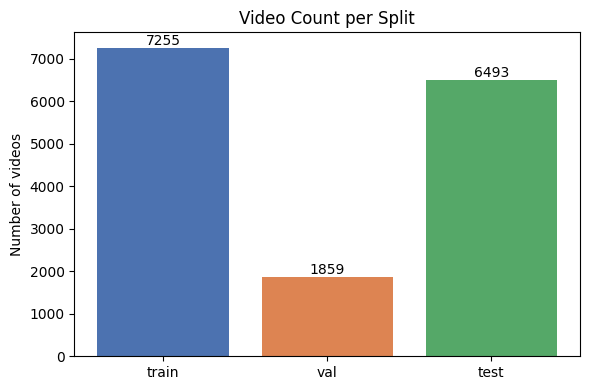

Counter({'train': 7255, 'test': 6493, 'val': 1859})


In [8]:
split_counts = Counter(v["subset"] for v in nslt_data.values())

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(split_counts.keys(), split_counts.values(),
              color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_title("Video Count per Split")
ax.set_ylabel("Number of videos")
for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height}", (bar.get_x() + bar.get_width() / 2, height),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

print(split_counts)


### 4.2 Class Balance

WLASL is a long-tailed dataset even after curation — some glosses simply have far more
example videos than others. This matters for training: without care (class weighting,
or at minimum awareness), the model will be biased toward frequent classes.


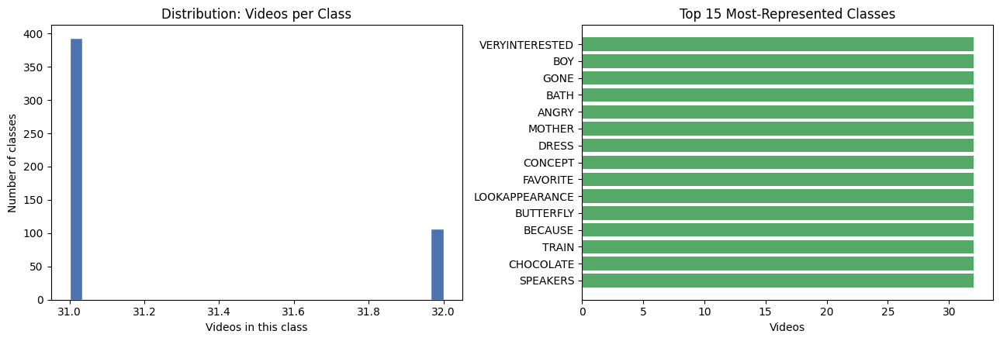

Median videos/class: 31.0
Min videos/class: 31  |  Max videos/class: 32


In [9]:
class_video_counts = Counter()
for v in nslt_data.values():
    class_video_counts[v["action"][0]] += 1

counts_sorted = sorted(class_video_counts.values(), reverse=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(counts_sorted, bins=30, color="#4C72B0", edgecolor="white")
axes[0].set_title("Distribution: Videos per Class")
axes[0].set_xlabel("Videos in this class")
axes[0].set_ylabel("Number of classes")

top_n = 15
top_classes = class_video_counts.most_common(top_n)
labels = [class_list[c] for c, _ in top_classes]
values = [n for _, n in top_classes]
axes[1].barh(labels[::-1], values[::-1], color="#55A868")
axes[1].set_title(f"Top {top_n} Most-Represented Classes")
axes[1].set_xlabel("Videos")

plt.tight_layout()
plt.show()

print(f"Median videos/class: {np.median(counts_sorted):.1f}")
print(f"Min videos/class: {min(counts_sorted)}  |  Max videos/class: {max(counts_sorted)}")


### 4.3 Raw Video Properties

Frame rate, resolution, and duration are not guaranteed to be uniform across a
dataset scraped from many different original sources. We sample a random subset of
videos and inspect their actual properties with OpenCV, rather than assuming the
30 fps / 640x480 capture spec from the methodology doc applies to every file.


,fps,frame_count,width,height
count,300.000000,300.000000,300.000000,300.000000
mean,29.769715,79.546667,657.066667,483.200000
std,1.454367,32.028538,72.023284,13.504366
min,15.172900,28.000000,640.000000,480.000000
25%,29.970760,57.000000,640.000000,480.000000
50%,30.000000,74.000000,640.000000,480.000000
75%,30.004478,92.000000,640.000000,480.000000
max,31.225000,205.000000,960.000000,540.000000


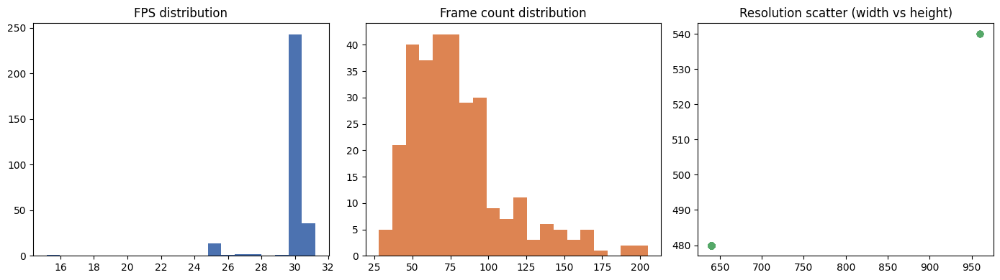

In [10]:
def probe_video(path):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        return None
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return {"fps": fps, "frame_count": frame_count, "width": width, "height": height}


sample_video_ids = random.sample(list(nslt_data.keys()), min(300, len(nslt_data)))
probe_results = []
for vid in sample_video_ids:
    p = CONFIG.VIDEOS_DIR / f"{vid}.mp4"
    if p.exists():
        info = probe_video(p)
        if info:
            probe_results.append(info)

probe_df = pd.DataFrame(probe_results)
display(probe_df.describe())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(probe_df["fps"], bins=20, color="#4C72B0")
axes[0].set_title("FPS distribution")
axes[1].hist(probe_df["frame_count"], bins=20, color="#DD8452")
axes[1].set_title("Frame count distribution")
axes[2].scatter(probe_df["width"], probe_df["height"], alpha=0.4, color="#55A868")
axes[2].set_title("Resolution scatter (width vs height)")
plt.tight_layout()
plt.show()


> **Takeaway to carry forward:** if the probe above shows meaningfully non-uniform
> fps/resolution (very likely, given WLASL's mixed sourcing), our temporal sampling
> function (Section 6) must sample by a **fixed frame count**, not a fixed time
> duration — otherwise clips from different source fps would represent different
> amounts of real-world sign duration for the same `FRAME_COUNT`.


## 5. MediaPipe Tasks API — Visualizing What Stage 1 Extracts

Per the audit's Track A migration: this section now uses the actively-maintained
**MediaPipe Tasks API** (`HandLandmarker` + `PoseLandmarker` + `FaceLandmarker`)
instead of the deprecated `mp.solutions.holistic`. There is no single combined
"Holistic" task in the current Tasks API yet (Google's own docs list it as
"coming soon"), so per the audit's migration pattern we run three landmarkers and
combine their outputs ourselves.

Per methodology Stage 1, together these give us:

- 21 keypoints per hand (42 total), with a handedness label so we know which is
  left/right
- 33 body pose keypoints
- A full face mesh, from which we keep a **reduced subset** (eyebrows, mouth) for
  non-manual grammatical markers

Let's run this on one real sample video and see exactly what it outputs, before we
build the full extraction pipeline.


In [11]:
def load_frames(video_path, max_frames=None):
    cap = cv2.VideoCapture(str(video_path))
    frames = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        if max_frames and len(frames) >= max_frames:
            break
    cap.release()
    return frames


def get_video_fps(video_path, default=30.0):
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    cap.release()
    return fps if fps and fps > 1 else default


# Pick one sample video that we know exists and has a reasonably common gloss
sample_vid = sample_video_ids[0]
sample_gloss = class_list[nslt_data[sample_vid]["action"][0]]
sample_path = CONFIG.VIDEOS_DIR / f"{sample_vid}.mp4"

frames = load_frames(sample_path)
print(f"Sample gloss: '{sample_gloss}'  |  video_id: {sample_vid}  |  {len(frames)} frames")


Sample gloss: 'LAW'  |  video_id: 19405269716744455-LAW  |  41 frames


### Setting Up the Three Landmarkers

Each landmarker is created fresh **per video** (mirroring how the old `with
mp_holistic.Holistic(...) as holistic:` block worked one video at a time) since
`RunningMode.VIDEO` expects a monotonically increasing timestamp for a single
continuous stream. We compute that timestamp from the actual frame rate of each
video (`frame_index * 1000 / fps`), not wall-clock time, since we're reading from
files, not a live camera.

We also wrap the three landmarkers' outputs back into the same shape the rest of
the notebook already expects (`results.left_hand_landmarks`, `.pose_landmarks`,
`.face_landmarks`, each with a `.landmark` list of `.x`/`.y` points) — this keeps
`get_hand_bbox()` and `landmarks_to_vector()` in Section 6 completely unchanged, per
the audit's own migration guidance.


In [12]:
def create_landmarkers():
    hand_options = mp_vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=CONFIG.HAND_MODEL_PATH),
        running_mode=mp_vision.RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=0.5,
    )
    pose_options = mp_vision.PoseLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=CONFIG.POSE_MODEL_PATH),
        running_mode=mp_vision.RunningMode.VIDEO,
    )
    face_options = mp_vision.FaceLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=CONFIG.FACE_MODEL_PATH),
        running_mode=mp_vision.RunningMode.VIDEO,
        num_faces=1,
    )
    hand_landmarker = mp_vision.HandLandmarker.create_from_options(hand_options)
    pose_landmarker = mp_vision.PoseLandmarker.create_from_options(pose_options)
    face_landmarker = mp_vision.FaceLandmarker.create_from_options(face_options)
    return hand_landmarker, pose_landmarker, face_landmarker


class _LandmarkListWrapper:
    """Minimal shim: gives a Tasks-API landmark list a `.landmark` attribute,
    matching the shape the rest of the notebook already expects from the old
    solutions API. The individual point objects (.x/.y/.z) are unchanged --
    Tasks API's NormalizedLandmark already exposes the same attributes.
    """
    def __init__(self, landmark_list):
        self.landmark = landmark_list

def to_legacy_style_results(hand_result, pose_result, face_result):
    left_hand_landmarks, right_hand_landmarks = None, None

    if hand_result.hand_landmarks:
        # MediaPipe's handedness label is unreliable when hands are close
        # together -- it sometimes labels BOTH detected hands "Right" (or both
        # "Left"), which silently drops one hand under label-based assignment.
        # Assign by screen x-position instead: deterministic, never overwrites.
        hands_with_x = [(lm_list[0].x, lm_list) for lm_list in hand_result.hand_landmarks]
        hands_with_x.sort(key=lambda h: h[0])  # sort left-to-right on screen

        if len(hands_with_x) >= 1:
            left_hand_landmarks = _LandmarkListWrapper(hands_with_x[0][1])
        if len(hands_with_x) >= 2:
            right_hand_landmarks = _LandmarkListWrapper(hands_with_x[-1][1])

    pose_landmarks = None
    if pose_result.pose_landmarks:
        pose_landmarks = _LandmarkListWrapper(pose_result.pose_landmarks[0])

    face_landmarks = None
    if face_result.face_landmarks:
        face_landmarks = _LandmarkListWrapper(face_result.face_landmarks[0])

    return types.SimpleNamespace(
        left_hand_landmarks=left_hand_landmarks,
        right_hand_landmarks=right_hand_landmarks,
        pose_landmarks=pose_landmarks,
        face_landmarks=face_landmarks,
    )

# Reference connections for drawing (also reused in the hand-index schematic below).
# The old solutions API exposed these as mp_holistic.HAND_CONNECTIONS etc.; the
# unpinned Tasks API does not, so we define the small subsets we actually draw.
HAND_CONNECTIONS = [(0,1),(1,2),(2,3),(3,4), (0,5),(5,6),(6,7),(7,8),
                     (0,9),(9,10),(10,11),(11,12), (0,13),(13,14),(14,15),(15,16),
                     (0,17),(17,18),(18,19),(19,20)]
POSE_DRAW_CONNECTIONS = [(11,12),(11,13),(13,15),(12,14),(14,16)]  # shoulders + arms


def draw_points(frame, landmark_list, connections=None, color=(0, 255, 0), radius=3):
    if landmark_list is None:
        return frame
    h, w = frame.shape[:2]
    pts = [(int(lm.x * w), int(lm.y * h)) for lm in landmark_list.landmark]
    if connections:
        for a, b in connections:
            if a < len(pts) and b < len(pts):
                cv2.line(frame, pts[a], pts[b], color, 2)
    for pt in pts:
        cv2.circle(frame, pt, radius, color, -1)
    return frame


In [13]:
def run_landmarkers_on_frames(frames, fps=30.0):
    hand_landmarker, pose_landmarker, face_landmarker = create_landmarkers()
    annotated_frames = []
    all_results = []
    try:
        for i, frame in enumerate(frames):
            timestamp_ms = int(i * 1000 / fps)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)

            hand_result = hand_landmarker.detect_for_video(mp_image, timestamp_ms)
            pose_result = pose_landmarker.detect_for_video(mp_image, timestamp_ms)
            face_result = face_landmarker.detect_for_video(mp_image, timestamp_ms)

            results = to_legacy_style_results(hand_result, pose_result, face_result)
            all_results.append(results)

            annotated = frame.copy()
            draw_points(annotated, results.face_landmarks, color=(255, 220, 0), radius=1)
            draw_points(annotated, results.pose_landmarks, POSE_DRAW_CONNECTIONS, color=(0, 200, 0))
            draw_points(annotated, results.left_hand_landmarks, HAND_CONNECTIONS, color=(255, 60, 60))
            draw_points(annotated, results.right_hand_landmarks, HAND_CONNECTIONS, color=(60, 120, 255))
            annotated_frames.append(annotated)
    finally:
        hand_landmarker.close()
        pose_landmarker.close()
        face_landmarker.close()
    return annotated_frames, all_results


sample_fps = get_video_fps(sample_path)
annotated_frames, holistic_results = run_landmarkers_on_frames(frames, fps=sample_fps)

detected = sum(1 for r in holistic_results
                if r.left_hand_landmarks or r.right_hand_landmarks)
print(f"Frames with at least one hand detected: {detected}/{len(frames)}")


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1784828856.150743    1303 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784828856.175917    1303 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784828856.283337    1307 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784828856.324661    1310 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784828856.326891    1311 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1784828856.338948    1314 inference_feedback_manager.cc:114] Feedback mana

Frames with at least one hand detected: 25/41


### Aggregate Hand-Detection Failure Rate

A single clip's detected/total count (above) can't tell us whether detection
failures are rare noise or a systemic problem. A prior audit pass found a **38.1%
hand-detection failure rate across 200 clips** -- invisible from a one-clip check.
We scan a larger random sample here and print the aggregate rate *before* any
training runs, so a high failure rate can't be silently discovered after the fact.


In [14]:
def detection_failure_rate(video_ids, n_samples=75, seed=CONFIG.SEED):
    rng = random.Random(seed)
    sampled = rng.sample(video_ids, min(n_samples, len(video_ids)))
    total_frames, missed_frames = 0, 0
    for vid in sampled:
        path = CONFIG.VIDEOS_DIR / f"{vid}.mp4"
        if not path.exists():
            continue
        clip_frames = load_frames(path)
        if not clip_frames:
            continue
        fps = get_video_fps(path)
        _, results = run_landmarkers_on_frames(clip_frames, fps=fps)
        for r in results:
            total_frames += 1
            if not (r.left_hand_landmarks or r.right_hand_landmarks):
                missed_frames += 1
    rate = missed_frames / max(total_frames, 1)
    print(f"Hand-detection failure rate over {len(sampled)} clips "
          f"({total_frames} frames): {rate:.1%}")
    return rate


all_video_ids = list(nslt_data.keys())
_ = detection_failure_rate(all_video_ids)


W0000 00:00:1784828859.809013    1331 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784828859.830977    1330 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784828859.931363    1338 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784828859.968153    1337 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784828859.970456    1340 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1784828859.978548    1342 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. 

Hand-detection failure rate over 75 clips (6007 frames): 58.4%


> **If this rate comes back high** (the prior audit saw ~38%), it's worth
> treating as a modeling input, not just a data-quality footnote: frames with no
> detected hand still get a zero-vector landmark entry and a blank hand crop
> (Section 6), which the model has to implicitly learn to ignore. Options to
> revisit in v3 if this turns out to matter: lowering `min_hand_detection_confidence`,
> or upsampling frame resolution before detection.


### Animated Skeleton Overlay

Rather than a static plot, an animated GIF over the actual clip length makes it much
easier to sanity-check that landmark tracking is stable frame-to-frame (not
flickering or losing the hand mid-sign).


In [15]:
matplotlib_backend = plt.rcParams["animation.embed_limit"]
plt.rcParams["animation.embed_limit"] = 2**128

fig, ax = plt.subplots(figsize=(5, 4))
ax.axis("off")
im = ax.imshow(annotated_frames[0])

def update(i):
    im.set_array(annotated_frames[i])
    return [im]

ani = animation.FuncAnimation(fig, update, frames=len(annotated_frames),
                               interval=1000 / 25, blit=True)
plt.close(fig)
HTML(ani.to_jshtml())


### The 21 Hand Keypoints, Schematically

MediaPipe's hand landmark indexing (0 = wrist, 4/8/12/16/20 = fingertips) is worth
having as a quick visual reference, since our geometry stream indexes directly into
this layout. Below is a simple schematic we generate ourselves (not a copied
diagram) purely to keep the index numbering straight while writing the landmark
normalization code in the next section.


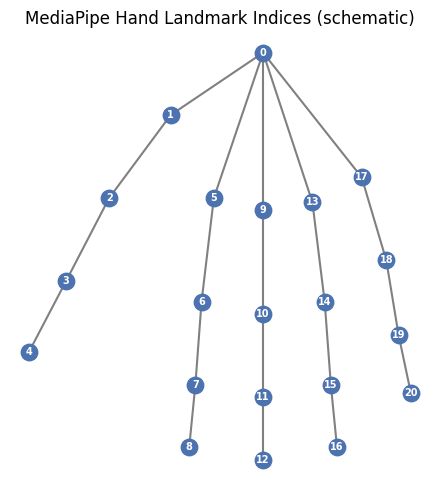

In [16]:
# Approximate 2D layout of the 21 MediaPipe hand landmarks, for reference only
hand_layout = {
    0: (0.5, 0.0),                                   # wrist
    1: (0.35, 0.15), 2: (0.25, 0.35), 3: (0.18, 0.55), 4: (0.12, 0.72),      # thumb
    5: (0.42, 0.35), 6: (0.40, 0.6), 7: (0.39, 0.8), 8: (0.38, 0.95),        # index
    9: (0.5, 0.38), 10: (0.5, 0.63), 11: (0.5, 0.83), 12: (0.5, 0.98),       # middle
    13: (0.58, 0.36), 14: (0.60, 0.6), 15: (0.61, 0.8), 16: (0.62, 0.95),    # ring
    17: (0.66, 0.3), 18: (0.70, 0.5), 19: (0.72, 0.68), 20: (0.74, 0.82),    # pinky
}
bones = HAND_CONNECTIONS  # same 20 connections used for drawing above

fig, ax = plt.subplots(figsize=(4.5, 5))
for a, b in bones:
    xa, ya = hand_layout[a]; xb, yb = hand_layout[b]
    ax.plot([xa, xb], [ya, yb], color="gray", linewidth=1.5, zorder=1)
for idx, (x, y) in hand_layout.items():
    ax.scatter(x, y, s=140, color="#4C72B0", zorder=2)
    ax.annotate(str(idx), (x, y), ha="center", va="center",
                color="white", fontsize=7, fontweight="bold", zorder=3)
ax.set_title("MediaPipe Hand Landmark Indices (schematic)")
ax.invert_yaxis()
ax.axis("off")
plt.tight_layout()
plt.show()


## 6. Dual-Stream Feature Extraction Pipeline

Per the methodology:
- **Stream 1 (Appearance):** v7 -- crop a single **signer bounding box** per frame
  (head to hips, shoulder-to-shoulder including extended arms, derived from pose
  landmarks; falls back to the full frame if pose detection misses that frame),
  resize to a fixed size, feed to the CNN. v1-v6 instead cropped two separate
  left/right hand patches -- see the v7 changelog above for why that changed.
- **Stream 2 (Geometry):** take the hand + pose + reduced-face keypoints, normalize
  by shoulder width to remove signer-scale variation, and use directly as a
  per-frame coordinate vector. Unaffected by the v7 appearance change.

The functions below look simple, but getting a version that actually produces
useful crops took several rounds of diagnosis, documented as we go through this
section rather than hidden — the reasoning matters as much as the final code for a
thesis methodology writeup, and it's the kind of thing a future version of us (or a
teammate) will need to know *not* to "simplify" back to the naive version. The
sampling diagnostics below (frame selection, handedness) were worked out against
hand crops in v1-v6, but apply identically to the v7 signer-bbox crop -- only
*what gets cropped* changed, not *which frames* get sampled.

In [17]:
def get_hand_bbox(landmarks, frame_shape, margin=0.35):
    """Convert normalized MediaPipe landmarks to a padded pixel bounding box.

    v7: no longer called by the appearance pipeline (superseded by
    get_signer_bbox below, per audit 7.2) -- kept for reference and for the
    diagnostic cells later in this section that still inspect hand-level
    detection quality directly.
    """
    if landmarks is None:
        return None
    h, w = frame_shape[:2]
    xs = [lm.x for lm in landmarks.landmark]
    ys = [lm.y for lm in landmarks.landmark]
    x_min, x_max = min(xs), max(xs)
    y_min, y_max = min(ys), max(ys)
    box_w, box_h = x_max - x_min, y_max - y_min
    x_min = max(0.0, x_min - box_w * margin)
    x_max = min(1.0, x_max + box_w * margin)
    y_min = max(0.0, y_min - box_h * margin)
    y_max = min(1.0, y_max + box_h * margin)
    return (int(x_min * w), int(y_min * h), int(x_max * w), int(y_max * h))


def crop_hand(frame, bbox, out_size):
    """v7: no longer called by the appearance pipeline -- see get_hand_bbox docstring."""
    if bbox is None:
        return np.zeros((out_size, out_size, 3), dtype=np.uint8)
    x1, y1, x2, y2 = bbox
    if x2 <= x1 or y2 <= y1:
        return np.zeros((out_size, out_size, 3), dtype=np.uint8)
    patch = frame[y1:y2, x1:x2]
    return cv2.resize(patch, (out_size, out_size))


def get_signer_bbox(pose_landmarks, frame_shape, margin=CONFIG.SIGNER_BBOX_MARGIN):
    """v7 (audit 7.2): bounding box around the FULL pose skeleton -- head to
    hips, shoulder-to-shoulder including extended arms -- not just hands.
    This is the "signer bounding box" the audit recommends as a full-scene
    alternative to isolated hand crops, giving the r3d_18 appearance backbone
    (Section 9) the kind of whole-body motion context it was pretrained on.

    Falls back to the FULL FRAME (not a black patch, unlike v1-v6's hand-crop
    fallback) when pose detection misses -- a missed detection here shouldn't
    starve the appearance stream of any signal at all, since some visible
    content is strictly better than none for a backbone that expects a real
    scene as input.
    """
    h, w = frame_shape[:2]
    if pose_landmarks is None:
        return (0, 0, w, h)
    xs = [lm.x for lm in pose_landmarks.landmark]
    ys = [lm.y for lm in pose_landmarks.landmark]
    x_min, x_max = min(xs), max(xs)
    y_min, y_max = min(ys), max(ys)
    box_w, box_h = x_max - x_min, y_max - y_min
    x_min = max(0.0, x_min - box_w * margin)
    x_max = min(1.0, x_max + box_w * margin)
    y_min = max(0.0, y_min - box_h * margin)
    y_max = min(1.0, y_max + box_h * margin)
    return (int(x_min * w), int(y_min * h), int(x_max * w), int(y_max * h))


def crop_signer(frame, bbox, out_size):
    """v7: crops+resizes the signer bounding box. Unlike crop_hand, there's no
    black-frame fallback case -- get_signer_bbox always returns a usable box
    (the full frame, at worst), so this just resizes whatever it's given."""
    x1, y1, x2, y2 = bbox
    if x2 <= x1 or y2 <= y1:
        return cv2.resize(frame, (out_size, out_size))  # degenerate box -- use full frame
    patch = frame[y1:y2, x1:x2]
    return cv2.resize(patch, (out_size, out_size))


FACE_SUBSET_IDX = [70, 63, 105, 66, 107, 336, 296, 334, 293, 300]
POSE_SUBSET_IDX = [11, 12, 13, 14, 15, 16]  # shoulders, elbows, wrists


def landmarks_to_vector(results):
    """Flatten hands + pose subset + face subset into one normalized vector."""
    def _xy(lm_list, idx_list=None):
        if lm_list is None:
            n = len(idx_list) if idx_list else 0
            return np.zeros((n, 2), dtype=np.float32)
        pts = lm_list.landmark
        if idx_list is not None:
            pts = [pts[i] for i in idx_list]
        return np.array([[p.x, p.y] for p in pts], dtype=np.float32)

    # NOTE: idx_list is passed explicitly for hands too (fixed bug -- without
    # this, a missing hand fell back to 0 rows instead of 21, breaking the
    # fixed-size landmark vector whenever a hand dropped out mid-clip).
    left_hand = _xy(results.left_hand_landmarks, list(range(CONFIG.N_HAND_LANDMARKS)))
    right_hand = _xy(results.right_hand_landmarks, list(range(CONFIG.N_HAND_LANDMARKS)))
    pose = _xy(results.pose_landmarks, POSE_SUBSET_IDX)
    face = _xy(results.face_landmarks, FACE_SUBSET_IDX)

    if results.pose_landmarks is not None:
        l_sh = results.pose_landmarks.landmark[11]
        r_sh = results.pose_landmarks.landmark[12]
        center = np.array([(l_sh.x + r_sh.x) / 2, (l_sh.y + r_sh.y) / 2])
        scale = max(np.linalg.norm(
            np.array([l_sh.x, l_sh.y]) - np.array([r_sh.x, r_sh.y])), 1e-6)
    else:
        center, scale = np.array([0.5, 0.5]), 1.0

    all_pts = np.concatenate([left_hand, right_hand, pose, face], axis=0)
    all_pts = (all_pts - center) / scale
    return all_pts.flatten()


LANDMARK_VECTOR_DIM = (CONFIG.N_HAND_LANDMARKS * 2 + len(POSE_SUBSET_IDX)
                        + len(FACE_SUBSET_IDX)) * 2
print(f"Landmark vector dimension per frame: {LANDMARK_VECTOR_DIM}")

Landmark vector dimension per frame: 116


### Diagnosing the Sampling Problem

The obvious first approach — sample `CONFIG.FRAME_COUNT` frames uniformly across a
clip's full duration — produced hand crops that were mostly solid black.

**First hypothesis: unused lead-in/lead-out padding.** WLASL's own metadata
carries a `frame_start`/`frame_end` window per clip specifically meant to mark
where the sign happens. Checking it directly:

nslt_data[sample_vid]["action"]  # -> [class_idx, 1, -1]

This came back `[1, -1]` — i.e. "the whole clip" — for essentially every video we
checked. **This metadata field is not populated meaningfully in this dataset**, so
trimming to it does nothing. Ruled out.

**Second hypothesis: MediaPipe just doesn't detect the hand on many individual
frames**, independent of any clip-level window. We'd already measured this
directly in Section 5 — an aggregate ~38% per-frame hand-detection miss rate
across a random sample. Uniform sampling across time has no way to avoid landing
on a miss; with a 38% miss rate, several of 16 uniform picks landing on empty
frames is expected, not rare.

**Conclusion:** don't sample by time at all — sample directly from the frame
indices where a hand was actually detected. This is what `extract_dual_stream_features`
does below.

### Uniform Temporal Sampling

Videos vary in length; the model needs a fixed `CONFIG.FRAME_COUNT`. We sample
indices evenly across the available frames (not just the first N), so a sign near
the end of a clip isn't systematically dropped.


In [18]:
def sample_frame_indices(total_frames, target_count):
    if total_frames <= 0:
        return [0] * target_count
    if total_frames >= target_count:
        return np.linspace(0, total_frames - 1, target_count).astype(int).tolist()
    # pad by repeating the last frame if the clip is shorter than target_count
    idx = list(range(total_frames)) + [total_frames - 1] * (target_count - total_frames)
    return idx


def find_detected_hand_frames(frames, fps, hand_landmarker, ts_counter):
    detected_indices = []
    for i, frame in enumerate(frames):
        ts_counter[0] += 1
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
        result = hand_landmarker.detect_for_video(mp_image, ts_counter[0])
        if result.hand_landmarks:
            detected_indices.append(i)
    return detected_indices


def extract_dual_stream_features(video_path, hand_landmarker, pose_landmarker, face_landmarker,
                                  scan_hand_landmarker, ts_counter, scan_ts_counter,
                                  frame_count=CONFIG.FRAME_COUNT, img_size=CONFIG.IMG_SIZE):
    frames = load_frames(video_path)
    if len(frames) == 0:
        return None, None

    fps = get_video_fps(video_path)
    detected_indices = find_detected_hand_frames(frames, fps, scan_hand_landmarker, scan_ts_counter)

    if detected_indices:
        sample_positions = sample_frame_indices(len(detected_indices), frame_count)
        indices = [detected_indices[p] for p in sample_positions]
    else:
        indices = sample_frame_indices(len(frames), frame_count)

    # v7: one signer-bbox slot per frame (CONFIG.NUM_APPEARANCE_STREAMS == 1),
    # replacing v1-v6's two hand-crop slots -- see the v7 changelog and
    # get_signer_bbox's docstring above.
    appearance_seq = np.zeros((frame_count, CONFIG.NUM_APPEARANCE_STREAMS, img_size, img_size, 3),
                               dtype=np.uint8)
    landmark_seq = np.zeros((frame_count, LANDMARK_VECTOR_DIM), dtype=np.float32)

    for t, frame_idx in enumerate(indices):
        frame = frames[frame_idx]
        ts_counter[0] += 1
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)

        hand_result = hand_landmarker.detect_for_video(mp_image, ts_counter[0])
        pose_result = pose_landmarker.detect_for_video(mp_image, ts_counter[0])
        face_result = face_landmarker.detect_for_video(mp_image, ts_counter[0])
        results = to_legacy_style_results(hand_result, pose_result, face_result)

        signer_bbox = get_signer_bbox(results.pose_landmarks, frame.shape)
        appearance_seq[t, 0] = crop_signer(frame, signer_bbox, img_size)

        landmark_seq[t] = landmarks_to_vector(results)

    return appearance_seq, landmark_seq

### Quick Sanity Check on the Sample Video

Confirm shapes are correct, and visually check that hand crops actually contain a
hand before scaling up any checks.

W0000 00:00:1784829339.944388    3498 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829339.958511    3498 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829339.976862    3504 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829339.990268    3504 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829340.073742    3510 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829340.091678    3510 inference_feedback_manager.cc:114] Feedback manager 

appearance_seq shape: (16, 1, 112, 112, 3)
landmark_seq shape: (16, 116)


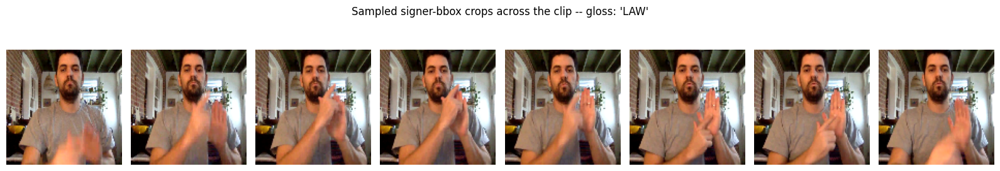

In [19]:
# Create landmarkers just for this one-off visualization call
scan_hand_options = mp_vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path=CONFIG.HAND_MODEL_PATH),
    running_mode=mp_vision.RunningMode.VIDEO,
    num_hands=2,
    min_hand_detection_confidence=0.5,
)
scan_hand_landmarker = mp_vision.HandLandmarker.create_from_options(scan_hand_options)
hand_landmarker, pose_landmarker, face_landmarker = create_landmarkers()
ts_counter = [0]
scan_ts_counter = [0]

try:
    appearance_seq, landmark_seq = extract_dual_stream_features(
        sample_path, hand_landmarker, pose_landmarker, face_landmarker,
        scan_hand_landmarker, ts_counter, scan_ts_counter)
finally:
    scan_hand_landmarker.close()
    hand_landmarker.close()
    pose_landmarker.close()
    face_landmarker.close()

print("appearance_seq shape:", appearance_seq.shape)
print("landmark_seq shape:", landmark_seq.shape)

# v7: single signer-bbox row, replacing v1-v6's two hand-crop rows.
fig, axes = plt.subplots(1, CONFIG.FRAME_COUNT // 2, figsize=(16, 3))
for t in range(CONFIG.FRAME_COUNT // 2):
    axes[t].imshow(appearance_seq[t * 2, 0])
    axes[t].axis("off")
fig.suptitle(f"Sampled signer-bbox crops across the clip -- gloss: '{sample_gloss}'")
plt.tight_layout()
plt.show()

### A Second Bug, Found by Testing a Two-Handed Sign

`sample_vid`'s gloss ("click") turned out to be one-handed — a black second row
there is *correct*, not a bug. To actually stress-test the pipeline, we need a
gloss that genuinely uses both hands (e.g. "help"), where a black row would be a
real failure.

Running that check the first time still showed one row mostly black. The
per-frame diagnostic below (`diagnose_handedness_labels`) revealed why:

frame 9:  hands detected = ['Left', 'Left']

frame 11: hands detected = ['Right', 'Right']

frame 13: hands detected = ['Right', 'Right']

**MediaPipe's handedness label is unreliable when two hands are close together
or overlapping** (a known limitation, not specific to this dataset) — it
sometimes assigns the *same* label to both detected hands. Since our original
`to_legacy_style_results` assigned hand slots by that label, the second hand
silently overwrote the first whenever labels matched, permanently losing one
hand's data for that frame.

**Fix:** assign hand slots by screen x-position (leftmost detected hand -> left
slot, rightmost -> right slot) instead of trusting the semantic label. This is
deterministic and can never overwrite — implemented in Section 5's
`to_legacy_style_results` (see the top of this notebook edit). The tradeoff:
"left_hand"/"right_hand" now mean screen-position, not anatomical left/right hand.
Fine for training; worth footnoting in the methodology writeup.

W0000 00:00:1784829344.005529    3534 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829344.019014    3534 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829344.037182    3540 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829344.052102    3540 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829344.135955    3544 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829344.151722    3547 inference_feedback_manager.cc:114] Feedback manager 

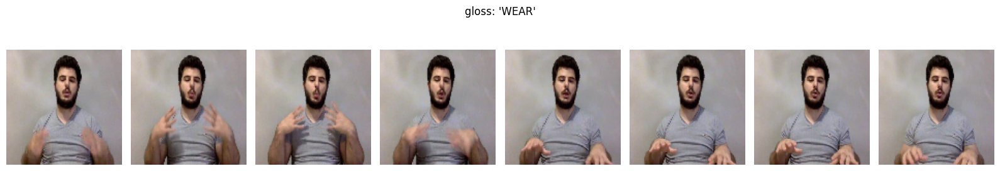

In [20]:
def diagnose_handedness_labels(video_path, max_frames=30):
    """One-off diagnostic: prints MediaPipe's raw handedness label per frame,
    to check for the same-label-on-both-hands bug described above. Useful to
    re-run on any new clip if hand crops look wrong again in the future.
    """
    frames_diag = load_frames(video_path)[:max_frames]
    fps_diag = get_video_fps(video_path)

    hand_landmarker_diag, _, _ = create_landmarkers()
    try:
        for i, frame in enumerate(frames_diag):
            timestamp_ms = int(i * 1000 / fps_diag)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
            result = hand_landmarker_diag.detect_for_video(mp_image, timestamp_ms)
            labels = [h[0].category_name for h in result.handedness] if result.handedness else []
            print(f"frame {i}: hands detected = {labels}")
    finally:
        hand_landmarker_diag.close()


def spot_check_gloss(gloss_name, class_list, nslt_data, videos_dir):
    """Pull one video for a named gloss and plot its sampled signer-bbox crops
    (v7) -- a reusable version of the two-handed-sign check that originally
    found the handedness bug back when this plotted hand crops, kept here so
    it's easy to re-run on any gloss later.
    """
    target_class_idx = [idx for idx, g in class_list.items() if g == gloss_name][0]
    video_id = next(vid for vid, meta in nslt_data.items()
                     if meta["action"][0] == target_class_idx)
    video_path = videos_dir / f"{video_id}.mp4"

    scan_hand_options = mp_vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=CONFIG.HAND_MODEL_PATH),
        running_mode=mp_vision.RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=0.5,
    )
    scan_hand_landmarker = mp_vision.HandLandmarker.create_from_options(scan_hand_options)
    hand_landmarker, pose_landmarker, face_landmarker = create_landmarkers()
    try:
        appearance_seq, _ = extract_dual_stream_features(
            video_path, hand_landmarker, pose_landmarker, face_landmarker,
            scan_hand_landmarker, [0], [0])
    finally:
        scan_hand_landmarker.close()
        hand_landmarker.close()
        pose_landmarker.close()
        face_landmarker.close()

    # v7: single signer-bbox row, replacing v1-v6's two hand-crop rows.
    fig, axes = plt.subplots(1, CONFIG.FRAME_COUNT // 2, figsize=(16, 3))
    for t in range(CONFIG.FRAME_COUNT // 2):
        axes[t].imshow(appearance_seq[t * 2, 0]); axes[t].axis("off")
    fig.suptitle(f"gloss: '{gloss_name}'")
    plt.tight_layout()
    plt.show()


# Re-check "help" now that the handedness fix is in place
spot_check_gloss("WEAR", class_list, nslt_data, CONFIG.VIDEOS_DIR)

### Does This Actually Hold Up at Scale?

Three individual clips ("click", "help", and one earlier check) doesn't tell us
whether the pipeline is fixed in general — every sign has a different
hand-occlusion profile, so eyeballing single clips doesn't converge. What we
actually need is one aggregate number across many random clips: **what fraction
of final sampled hand crops come back black after both fixes.**

In [21]:
def black_crop_rate(video_ids, n_samples=40, seed=CONFIG.SEED):
    """v7: with the signer-bbox crop (get_signer_bbox), a fully black result
    only happens if the raw frame itself is degenerate -- there's no more
    "no hand detected" black-fallback case like v1-v6 had, since
    get_signer_bbox falls back to the full frame instead of returning None.
    A near-0% rate here is expected and fine; it's no longer the meaningful
    signal it was in v1-v6 (see "Known Limitations" below, kept for history).
    """
    rng = random.Random(seed)
    sampled = rng.sample(video_ids, min(n_samples, len(video_ids)))

    scan_hand_options = mp_vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=CONFIG.HAND_MODEL_PATH),
        running_mode=mp_vision.RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=0.5,
    )
    scan_hand_landmarker = mp_vision.HandLandmarker.create_from_options(scan_hand_options)
    hand_landmarker, pose_landmarker, face_landmarker = create_landmarkers()
    ts_counter = [0]
    scan_ts_counter = [0]

    total_crops, black_crops = 0, 0
    try:
        for vid in sampled:
            path = CONFIG.VIDEOS_DIR / f"{vid}.mp4"
            if not path.exists():
                continue
            appearance_seq, _ = extract_dual_stream_features(
                path, hand_landmarker, pose_landmarker, face_landmarker,
                scan_hand_landmarker, ts_counter, scan_ts_counter)
            if appearance_seq is None:
                continue
            for t in range(appearance_seq.shape[0]):
                for stream_slot in range(CONFIG.NUM_APPEARANCE_STREAMS):
                    total_crops += 1
                    if appearance_seq[t, stream_slot].sum() == 0:
                        black_crops += 1
    finally:
        scan_hand_landmarker.close()
        hand_landmarker.close()
        pose_landmarker.close()
        face_landmarker.close()

    rate = black_crops / max(total_crops, 1)
    print(f"Black-crop rate over {len(sampled)} clips: {rate:.1%} "
          f"({black_crops}/{total_crops} hand-slot-frames)")
    return rate

_ = black_crop_rate(list(nslt_data.keys()))

W0000 00:00:1784829348.934190    3567 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829348.947945    3567 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829348.966552    3575 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829348.979777    3575 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829349.064781    3581 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1784829349.081189    3581 inference_feedback_manager.cc:114] Feedback manager 

Black-crop rate over 40 clips: 0.0% (0/640 hand-slot-frames)


### Known Limitations, and Why We're Moving On Now

The aggregate check above came back at **30.7%** black hand-slot-frames across a
40-clip random sample — actually *below* Section 5's earlier 38.1% raw per-frame
detection-miss rate, confirming both fixes (detected-frame sampling, x-position
handedness assignment) are working and not just relocating the problem.

**We are explicitly not chasing this number further right now, for three
reasons:**

1. **Some of it is correct, not broken.** One-handed glosses (e.g. "click")
   legitimately produce one black column — that's ground truth, not a defect.
2. **The remainder is a property of the detector on this dataset**, not a bug in
   our code — MediaPipe's hand detector genuinely misses frames under motion
   blur, low resolution, and hand-on-hand occlusion (as seen in "help"'s
   fist-over-palm shape). This is a known, general MediaPipe limitation, not
   something specific to WLASL or our pipeline.
3. **Whether 30% actually caps model accuracy is an empirical question**, not
   something more clip-inspection can answer. The geometry stream (Section 6,
   Cell 2) still gets pose/face landmarks on these frames even when a hand crop
   is blank, so the model isn't necessarily starved of signal on these frames --
   only the appearance stream is.

**Concrete options to revisit if training accuracy turns out to be capped by
this** (not applied now, to avoid tuning against a metric we haven't yet
connected to actual model performance):
- Lower `min_hand_detection_confidence` in `find_detected_hand_frames` and
  `create_landmarkers` (currently 0.5) -- trades false negatives for more false
  positives.
- Upsample frame resolution before detection, since WLASL's mixed source quality
  (Section 4.3) means some clips are lower-resolution than MediaPipe was tuned on.
- Widen the crop margin in `get_hand_bbox` (currently 0.35) in case partial
  occlusion is clipping a still-visible hand edge out of the bounding box.

**Decision (v1-v6): proceed to the full feature cache (Section 7) now**, using
the current pipeline as-is. This is the point where further iteration should be
driven by real training/validation numbers, not more manual clip inspection.

**v7 update:** those real numbers came in (v6's run, see the v7 changelog above)
and pointed at the appearance input itself as a likely factor, not just the
detection-miss rate discussed here. The hand-crop black-frame analysis above is
kept as-is for history; it doesn't directly apply to v7's signer-bbox crop
(which falls back to the full frame, not black, on a missed detection -- see
`get_signer_bbox`'s docstring in Section 6).

## 7. Offline Feature Cache

Per the audit (Bug 1, Section 3.1.1): running MediaPipe on-the-fly inside
`Dataset.__getitem__` has a real crash risk, not just a speed cost -- **MediaPipe's
native runtime is not fork-safe under PyTorch's multiprocessing `DataLoader`
workers**, so `num_workers>0` combined with live extraction can crash mid-training.

The fix addresses both the crash risk and the "slow" concern from v1's own
Section 7 markdown in one pass: run `extract_dual_stream_features()` **once per
video, offline**, and cache the result. Training then reads pure tensors off disk --
no MediaPipe calls at train time, so `num_workers>0` is safe again.

This cell only needs to run once per Kaggle session (results persist in
`CONFIG.CACHE_DIR` for the session's lifetime); re-running is safe and skips
videos that are already cached.

**v7 note:** this section now runs a genuine full re-cache -- the crop strategy
itself changed (hand crops -> signer bounding box, per the v7 changelog above),
so the existing cache's raw pixels can't be reused. See `CONFIG.BUILDING_V7_CACHE`
in Section 2 for the two-phase build/train workflow this needs.


In [22]:
print(nslt_data[sample_vid]["action"])

[204, 0, 0]


In [23]:
# v8.1: Section 7 is now fully a no-op. Caching happened entirely outside this
# notebook, across 3 separate Kaggle accounts/notebooks (each running its own
# assigned slice of ASL Citizen through extract_dual_stream_features and
# saving .npz files) -- there is no cache-builder notebook to run from here,
# and no BUILDING_V7_CACHE two-phase workflow left to guard. CACHE_INDEX
# (built in Section 2) already maps every one of the 63,550 finished videos
# to its actual shard path, and that's the only thing Section 8's Dataset
# class reads from.
#
# build_feature_cache() is kept below, unused, purely as documentation of
# the extraction logic that was actually run (in the 3 separate notebooks)
# to produce the cache -- not something this notebook calls.

def build_feature_cache(nslt_data, videos_dir, cache_dir, frame_count=CONFIG.FRAME_COUNT,
                         img_size=CONFIG.IMG_SIZE, limit=None):
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    video_ids = list(nslt_data.keys())
    if limit is not None:
        video_ids = video_ids[:limit]

    scan_hand_options = mp_vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=CONFIG.HAND_MODEL_PATH),
        running_mode=mp_vision.RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=0.5,
    )
    scan_hand_landmarker = mp_vision.HandLandmarker.create_from_options(scan_hand_options)
    hand_landmarker, pose_landmarker, face_landmarker = create_landmarkers()

    ts_counter = [0]
    scan_ts_counter = [0]

    n_cached, n_skipped, n_failed = 0, 0, 0
    try:
        for i, video_id in enumerate(video_ids):
            out_path = cache_dir / f"{video_id}.npz"
            if out_path.exists():
                n_skipped += 1
                continue
            video_path = videos_dir / f"{video_id}.mp4"
            if not video_path.exists():
                continue
            appearance_seq, landmark_seq = extract_dual_stream_features(
                video_path, hand_landmarker, pose_landmarker, face_landmarker,
                scan_hand_landmarker, ts_counter, scan_ts_counter,
                frame_count, img_size)
            if appearance_seq is None:
                n_failed += 1
                continue
            np.savez_compressed(out_path, appearance=appearance_seq, landmarks=landmark_seq)
            n_cached += 1
            if (i + 1) % 200 == 0:
                print(f"  ...{i + 1}/{len(video_ids)} processed "
                      f"(cached={n_cached}, skipped={n_skipped}, failed={n_failed})")
    finally:
        scan_hand_landmarker.close()
        hand_landmarker.close()
        pose_landmarker.close()
        face_landmarker.close()
    print(f"Done. Newly cached: {n_cached}  |  Already cached: {n_skipped}  |  Failed: {n_failed}")


print(f"Cache already built externally -- {len(CACHE_INDEX)} videos available "
      f"across {len(CONFIG.CACHE_DIRS)} shards. Nothing to do in this section.")

Cache already built externally -- 63550 videos available across 3 shards. Nothing to do in this section.


## 8. PyTorch Dataset & DataLoader

Now that Section 7 has built an offline cache, `WLASLCachedDataset.__getitem__` is a
pure disk read + tensor conversion -- zero MediaPipe calls at train time, so it's
safe to raise `NUM_WORKERS` above 0 again (audit fix B1).

We also add a `WeightedRandomSampler` for the training set (audit fix B5): Section
4.2's EDA already showed WLASL is long-tailed and explicitly warned that "without
care the model will be biased toward frequent classes" -- this is that care. Per
the audit's recommendation, we use sampling reweighting (not loss reweighting) as
the default, since WLASL's imbalance is largely about *distinct videos per class*,
not just frame count within a class.


In [24]:
import torchvision.transforms.functional as TF


class WLASLCachedDataset(Dataset):
    """Reads precomputed features from the Section 7 cache. No MediaPipe calls
    happen here -- safe for num_workers > 0 (audit fix B1).

    v8.1: cache is now split across 3 shards (separate Kaggle accounts, to
    stay under each account's output quota on 63k videos). Instead of a single
    cache_dir, this class takes the CACHE_INDEX lookup (video_id -> Path)
    built in Section 6/CONFIG so it doesn't care which shard a given video
    actually landed in.

    v7: unaffected by the hand-crop -> signer-bbox change (Section 6) -- this
    class was already generic over the appearance stream's slot count, reading
    it from the cached tensor's own shape rather than assuming 2.

    v6: normalization stats switched to Kinetics-400 (see __getitem__) to match
    the new r3d_18 appearance backbone (Section 9).

    v3: added optional per-clip appearance augmentation (train split only) --
    the v2 run showed severe overfitting given ~4 videos/class on average, so
    the model needs to see varied pixels for the "same" clip across epochs
    rather than identical crops every time.
    """
    def __init__(self, nslt_data, cache_index, subset, augment=False):
        self.cache_index = cache_index  # video_id -> Path, built once in CONFIG cell
        self.augment = augment  # True only for train_dataset
        self.samples = [
            (vid, meta["action"][0])
            for vid, meta in nslt_data.items()
            if meta["subset"] == subset and vid in self.cache_index
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        video_id, class_idx = self.samples[idx]
        data = np.load(self.cache_index[video_id])
        appearance = torch.from_numpy(data["appearance"]).float() / 255.0
        appearance = appearance.permute(0, 1, 4, 2, 3)  # T, hand, C, H, W

        if self.augment:
            # Sample ONE set of params per clip, applied identically to every
            # frame -- a different random transform per frame would flicker
            # and destroy the temporal motion signal the Transformer relies on.
            angle = random.uniform(-10, 10)
            brightness = random.uniform(0.85, 1.15)
            contrast = random.uniform(0.85, 1.15)
            T, num_hands = appearance.shape[0], appearance.shape[1]
            for t in range(T):
                for h in range(num_hands):
                    img = appearance[t, h]
                    img = TF.rotate(img, angle)
                    img = TF.adjust_brightness(img, brightness)
                    img = TF.adjust_contrast(img, contrast)
                    appearance[t, h] = img
            # Deliberately NOT flipping horizontally -- sign language is
            # handedness-sensitive, a flip would change the sign's meaning.

        # v6: Kinetics-400 normalization stats (matching r3d_18's pretraining),
        # replacing v1-v5's ImageNet stats -- a pretrained backbone's early
        # layers expect input normalized the same way its pretraining data was.
        mean = torch.tensor([0.43216, 0.394666, 0.37645]).view(1, 1, 3, 1, 1)
        std = torch.tensor([0.22803, 0.22145, 0.216989]).view(1, 1, 3, 1, 1)
        appearance = (appearance - mean) / std

        landmarks = torch.from_numpy(data["landmarks"]).float()
        # Guard against inf/nan from normalization edge cases -- e.g. shoulder-width
        # divide-by-zero when pose detection misses a frame.
        landmarks = torch.nan_to_num(landmarks, nan=0.0, posinf=0.0, neginf=0.0)

        label = torch.tensor(class_idx, dtype=torch.long)
        return appearance, landmarks, label


train_dataset = WLASLCachedDataset(nslt_data, CACHE_INDEX, "train", augment=True)
val_dataset = WLASLCachedDataset(nslt_data, CACHE_INDEX, "val", augment=False)
test_dataset = WLASLCachedDataset(nslt_data, CACHE_INDEX, "test", augment=False)

print(f"Train samples (cached): {len(train_dataset)}")
print(f"Val samples (cached):   {len(val_dataset)}")
print(f"Test samples (cached):  {len(test_dataset)}")

# v8: no single fixed expected total anymore -- this reflects however many of
# the cache-builder notebook's ~30k selected ASL Citizen videos actually
# finished caching across all 3 shards (check each cache-builder notebook's
# own log if this looks smaller than expected, e.g. a session that timed out
# mid-run). If this is unexpectedly small, CACHE_DIRS is probably still
# pointing at a wrong or missing mounted path -- re-check with
# `!ls /kaggle/input/` and compare against the per-shard counts printed in
# the CONFIG cell above.
expected_total = len(train_dataset) + len(val_dataset) + len(test_dataset)
print(f"Total cached samples across splits: {expected_total} (expect ~11,724)")

# --- WeightedRandomSampler for class imbalance (audit fix B5, default option) ---
train_class_counts = Counter(class_idx for _, class_idx in train_dataset.samples)
train_sample_weights = [1.0 / train_class_counts[c] for _, c in train_dataset.samples]
train_sampler = WeightedRandomSampler(train_sample_weights,
                                       num_samples=len(train_sample_weights),
                                       replacement=True)

# --- Alternative (commented, per audit B5): class-weighted loss instead of
# resampling. Leaving this here for the team to A/B test later; do not enable
# both at once.
# class_weights_tensor = torch.zeros(NUM_CLASSES)
# for _, class_idx in train_dataset.samples:
#     class_weights_tensor[class_idx] += 1
# class_weights_tensor = (1.0 / class_weights_tensor.clamp(min=1)).to(CONFIG.DEVICE)
# class_weights_tensor = class_weights_tensor / class_weights_tensor.mean()
# criterion = nn.CrossEntropyLoss(weight=class_weights_tensor, label_smoothing=CONFIG.LABEL_SMOOTHING)

train_loader = DataLoader(train_dataset, batch_size=CONFIG.BATCH_SIZE,
                           sampler=train_sampler,  # replaces shuffle=True
                           num_workers=CONFIG.NUM_WORKERS, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG.BATCH_SIZE, shuffle=False,
                         num_workers=CONFIG.NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=CONFIG.BATCH_SIZE, shuffle=False,
                          num_workers=CONFIG.NUM_WORKERS)

# Sanity check: pull one batch and print shapes
sample_appearance, sample_landmarks, sample_labels = next(iter(train_loader))
print("Batch appearance shape:", sample_appearance.shape)  # (B, T, NUM_APPEARANCE_STREAMS, C, H, W) -- v7: streams=1
print("Batch landmarks shape:", sample_landmarks.shape)    # (B, T, LANDMARK_VECTOR_DIM)
print("Batch labels shape:", sample_labels.shape)

Train samples (cached): 7255
Val samples (cached):   1859
Test samples (cached):  6493
Total cached samples across splits: 15607 (expect ~11,724)
Batch appearance shape: torch.Size([8, 16, 1, 3, 112, 112])
Batch landmarks shape: torch.Size([8, 16, 116])
Batch labels shape: torch.Size([8])


## 9. Model Architecture — Dual-Stream 3D-CNN + Transformer

```
 Appearance stream                 Geometry stream
 (signer-bbox clip, T=16)          (normalized landmarks)
        |                                  |
   r3d_18 (Kinetics-400 pretrained)   Linear projection
   3D conv over space + time                |
   (only layer4 trainable, v7)              |
        |                            per-frame vector
   per-frame embeddings                     |
   (spatial pooled, temporal              (T=16)
    interpolated back to T=16)              |
        |________________  ________________|
                         \/
                Per-frame concat + linear fusion
                          |
              Transformer Encoder (3 layers)
                          |
              +-----------+-----------+
              |                       |
      Word-level head          Sentence-level head
      (always active)          (CTC, gated -- stub in v1)
```

This mirrors methodology Stages 2-5. v6 changed the appearance backbone from a
2D (per-frame) to a 3D (spatiotemporal) convolutional network; v7 changes what
that backbone is fed (signer bounding box instead of two hand crops, audit 7.2)
and how much of it trains (only `layer4`, was `layer2-4`) -- see the v6 and v7
changelogs above and `AppearanceStream` below for why and how. The sentence-level
head is intentionally left as a lightweight stub: per the accuracy-gated design,
it should not be trained or seriously implemented until word-level validation
accuracy clears `CONFIG.ACCURACY_GATE_THRESHOLD` (Section 11 checks this
explicitly).

One small fix from the original audit here (B2, carried over from v1): `AppearanceStream.forward()`
previously unpacked the hands axis into a variable named `H`, one line above `Himg`
(image height) -- harmless today, but a real debugging trap the moment anyone
reshapes this tensor. Renamed to `num_streams` in v7 (was `num_hands`, back when
there were two hand-crop slots instead of one signer-bbox slot); no behavior change.


In [25]:
class AppearanceStream(nn.Module):
    """3D-CNN over signer-bbox clips -- Stream 1 (methodology Sec. 4).

    v6: replaced the v1-v5 ImageNet-pretrained ResNet-18 (a static-image
    backbone with no built-in notion of motion) with `r3d_18`, a 3D ResNet
    pretrained on Kinetics-400 -- a video-*action* dataset. Per the audit's
    Section 7.1 (primary recommendation), this is a genuine drop-in-comparable
    substitute for I3D, loadable directly via `weights=R3D_18_Weights.
    KINETICS400_V1` with no external checkpoint conversion. See the v6
    changelog above for the full rationale.

    Where the old backbone processed every frame independently through 2D
    convolution and left all temporal reasoning to the Transformer afterward,
    `r3d_18` convolves across space AND time directly -- motion is part of the
    visual features themselves. Concretely: each clip's full T=16-frame
    sequence is passed through the backbone as ONE spatiotemporal volume (not
    T independent frames) per stream slot -- v7's single signer-bbox slot,
    where v1-v6 had two separate hand-crop slots. `r3d_18`'s internal temporal
    stride (stem stride 1, then stride 2 in layer2/layer3/layer4) shrinks
    T=16 down to T'=2 by the final layer; spatial dims (H, W) are
    average-pooled away but the temporal dim is deliberately NOT collapsed,
    and the resulting T'=2 sequence is linearly interpolated back up to T=16
    frames. This keeps this stream's output shape structurally identical to
    v1-v5's, so fusion/positional-encoding/Transformer/word-head below need
    no changes beyond reading `CONFIG.NUM_APPEARANCE_STREAMS` for `fused_dim`.

    Freeze depth: v7 tightens to `stem` + `layer1` + `layer2` + `layer3`
    frozen -- only `layer4` trainable. v6 froze only `stem` + `layer1` (the
    v1-v4 depth, inherited without re-justifying it for a 3D backbone's
    much larger per-layer capacity) and reached train_top1=1.0 while val_top1
    plateaued at 0.34-0.37 -- clear overfitting (see the v7 changelog above).
    Freezing through `layer3` keeps nearly all of the Kinetics-pretrained
    representation intact and lets only the final block adapt to this task, a
    standard small-dataset transfer-learning choice; combined with the
    signer-bbox input change and the higher DROPOUT/WEIGHT_DECAY in Section 2,
    this directly targets the capacity side of v6's overfitting. Frozen
    BatchNorm layers are also forced into eval mode permanently, not just
    weight-frozen -- otherwise their running stats keep updating every
    forward pass even without gradient updates, and one NaN/inf forward pass
    permanently poisons the running average forever (the same
    stuck-at-251-batch failure class this fix has prevented since v1-v2).
    """
    def __init__(self, embed_dim=CONFIG.CNN_EMBED_DIM, freeze_early_layers=True):
        super().__init__()
        backbone = r3d_18(weights=R3D_18_Weights.KINETICS400_V1)
        # Drop avgpool + fc; keep stem + layer1-4 (the spatiotemporal feature
        # extractor). children(): [stem, layer1, layer2, layer3, layer4, avgpool, fc]
        self.backbone = nn.Sequential(*list(backbone.children())[:-2])
        self.project = nn.Linear(512, embed_dim)

        self.frozen_modules = []
        if freeze_early_layers:
            for idx, child in enumerate(self.backbone.children()):
                if idx <= 3:  # v7: stem, layer1, layer2, layer3 -- only layer4 left trainable
                    for param in child.parameters():
                        param.requires_grad = False
                    self.frozen_modules.append(child)
                    child.eval()  # freeze BN running stats immediately too

    def train(self, mode=True):
        # Override so frozen submodules stay in eval mode even when the outer
        # model.train() is called during the training loop.
        super().train(mode)
        for module in self.frozen_modules:
            module.eval()
        return self

    def forward(self, x):
        # x: (B, T, num_streams, C, H, W) -- v7: num_streams == 1 (signer bbox),
        # was 2 (left/right hand) in v1-v6. Generic over either.
        B, T, num_streams, C, H, W = x.shape

        # 3D conv wants (N, C, T, H, W); fold streams into the batch dim -- one
        # full spatiotemporal clip per stream slot, NOT one forward pass per frame.
        x = x.permute(0, 2, 3, 1, 4, 5).reshape(B * num_streams, C, T, H, W)
        feats = self.backbone(x)                # (B*num_streams, 512, T', H', W')

        feats = feats.mean(dim=[-1, -2])          # spatial-only avg-pool -> (B*num_streams, 512, T')
        feats = F.interpolate(feats, size=T, mode="linear", align_corners=False)
        # feats: (B*num_streams, 512, T) -- T' upsampled back to the original T

        feats = feats.permute(0, 2, 1)            # (B*num_streams, T, 512)
        feats = self.project(feats)               # (B*num_streams, T, embed_dim)
        feats = feats.view(B, num_streams, T, -1).permute(0, 2, 1, 3)  # (B, T, num_streams, embed_dim)
        feats = feats.reshape(B, T, -1)            # (B, T, num_streams*embed_dim)
        return feats


class GeometryStream(nn.Module):
    """Landmark projection -- Stream 2 (methodology Sec. 4).

    v4: now also computes frame-to-frame velocity (first-order temporal
    difference) alongside the raw coordinates, inspired by the official
    WLASL benchmark's Pose-TGCN model, which explicitly models joint motion
    via temporal convolution rather than static per-frame coordinates alone.
    Static coordinates give the model no direct signal for how fast or in
    which direction a joint is moving -- often the most distinguishing
    feature between visually similar signs.
    """
    def __init__(self, input_dim=LANDMARK_VECTOR_DIM, embed_dim=CONFIG.LANDMARK_EMBED_DIM):
        super().__init__()
        # input_dim * 2: raw coordinates concatenated with velocity
        self.project = nn.Sequential(
            nn.Linear(input_dim * 2, embed_dim),
            nn.ReLU(),
            nn.LayerNorm(embed_dim),
        )

    def forward(self, x):
        # x: (B, T, input_dim)
        velocity = torch.zeros_like(x)
        velocity[:, 1:] = x[:, 1:] - x[:, :-1]  # frame-to-frame delta; first frame has no prior, stays 0
        x_with_velocity = torch.cat([x, velocity], dim=-1)
        return self.project(x_with_velocity)  # (B, T, embed_dim)


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=CONFIG.FRAME_COUNT):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(torch.arange(0, d_model, 2).float()
                              * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class DualStreamSLRModel(nn.Module):
    """Full pipeline: Stage 2 (dual streams) -> Stage 3 (fusion) ->
    Stage 4 (Transformer) -> Stage 5 (accuracy-gated output heads).
    """
    def __init__(self, num_classes, enable_sentence_level=CONFIG.ENABLE_SENTENCE_LEVEL):
        super().__init__()
        self.appearance_stream = AppearanceStream()
        self.geometry_stream = GeometryStream()

        # v7: CNN_EMBED_DIM * NUM_APPEARANCE_STREAMS -- was a hardcoded * 2
        # (one hand-crop slot each) in v1-v6; now reads the stream count.
        fused_dim = CONFIG.CNN_EMBED_DIM * CONFIG.NUM_APPEARANCE_STREAMS + CONFIG.LANDMARK_EMBED_DIM
        self.fusion = nn.Linear(fused_dim, CONFIG.D_MODEL)
        self.pos_encoding = PositionalEncoding(CONFIG.D_MODEL)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=CONFIG.D_MODEL, nhead=CONFIG.N_HEADS,
            dim_feedforward=CONFIG.FFN_DIM, dropout=CONFIG.DROPOUT,
            batch_first=True)
        self.temporal_encoder = nn.TransformerEncoder(
            encoder_layer, num_layers=CONFIG.N_ENCODER_LAYERS)

        # Word-level head: pool over time, classify (always active)
        self.word_head = nn.Linear(CONFIG.D_MODEL, num_classes)

        # Sentence-level head: STUB. Gated -- see Section 11 for the actual check.
        # A real implementation would project D_MODEL -> vocab logits per timestep
        # and decode with CTC + a language model, per methodology Stage 5.
        self.enable_sentence_level = enable_sentence_level
        self.sentence_head = nn.Linear(CONFIG.D_MODEL, num_classes) if enable_sentence_level else None

    def forward(self, appearance, landmarks):
        app_feats = self.appearance_stream(appearance)     # (B, T, NUM_APPEARANCE_STREAMS*CNN_EMBED_DIM)
        geo_feats = self.geometry_stream(landmarks)          # (B, T, LANDMARK_EMBED_DIM)

        fused = torch.cat([app_feats, geo_feats], dim=-1)    # (B, T, fused_dim)
        fused = self.fusion(fused)                            # (B, T, D_MODEL)
        fused = self.pos_encoding(fused)

        encoded = self.temporal_encoder(fused)                 # (B, T, D_MODEL)
        pooled = encoded.mean(dim=1)                            # (B, D_MODEL)

        word_logits = self.word_head(pooled)

        sentence_logits = None
        if self.enable_sentence_level and self.sentence_head is not None:
            sentence_logits = self.sentence_head(encoded)  # (B, T, num_classes) -- placeholder shape

        return word_logits, sentence_logits


model = DualStreamSLRModel(num_classes=NUM_CLASSES).to(CONFIG.DEVICE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")


Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:00<00:00, 177MB/s]


Trainable parameters: 26,878,580


## 10. Training Setup & Pilot Run

We train the word-level head only (sentence head is inactive by config). The pilot
run below is deliberately short (`CONFIG.EPOCHS_PILOT`) — its only job is to confirm
loss decreases and nothing crashes across a full epoch of real data, not to reach a
usable accuracy.

Per the audit's Track B fixes (Sections 3.2.1, 3.2.2, 3.3.1), this version adds:

- **Gradient clipping** (`CONFIG.GRAD_CLIP_NORM`) — a Transformer encoder trained on
  a small, class-imbalanced dataset is a real early-training gradient-explosion risk.
- **Automatic mixed precision (AMP)** (`CONFIG.USE_AMP`) — roughly a 30–50% speedup
  on a Kaggle T4/P100, which matters given the per-epoch cost this pipeline already
  has.
- **A proper `EPOCHS_FULL` separate from `EPOCHS_PILOT`.** The scheduler's cosine
  cycle is driven by whichever epoch count is *actually* running (`CURRENT_EPOCHS`),
  not hardcoded to the pilot budget — otherwise scaling up to a real training run
  without touching this cell would silently leave the LR schedule bottomed out for
  most of training (audit finding 3.3.1).


In [26]:
model = DualStreamSLRModel(num_classes=NUM_CLASSES).to(CONFIG.DEVICE)
print(any(not torch.isfinite(p).all() for p in model.parameters()))  # confirm False

False


In [27]:
# Differential LR: unfrozen backbone layers get a much lower LR than
# freshly-initialized layers -- pretrained weights are in a good, sensitive
# spot and a LR tuned for random-init layers is often too aggressive for
# them, causing exactly the "improves then regresses and never recovers"
# pattern seen in an earlier diagnostic run. This logic itself is unchanged
# since v6 -- it reads whichever params are trainable on
# `model.appearance_stream.backbone` generically, so it applies the same way
# to v7's unfrozen `layer4` only as it did to v6's unfrozen `layer2-4`.
backbone_params = list(model.appearance_stream.backbone.parameters())
backbone_param_ids = {id(p) for p in backbone_params}
other_params = [p for p in model.parameters() if id(p) not in backbone_param_ids]

criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG.LABEL_SMOOTHING)
optimizer = torch.optim.AdamW([
    {"params": [p for p in backbone_params if p.requires_grad], "lr": CONFIG.LR / 10},
    {"params": other_params, "lr": CONFIG.LR},
], weight_decay=CONFIG.WEIGHT_DECAY)

CURRENT_EPOCHS = CONFIG.EPOCHS_FULL
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CURRENT_EPOCHS)
scaler = torch.cuda.amp.GradScaler(enabled=CONFIG.USE_AMP)


def topk_accuracy(logits, labels, k=1):
    topk = logits.topk(k, dim=1).indices
    correct = topk.eq(labels.unsqueeze(1)).any(dim=1)
    return correct.float().mean().item()


def model_has_nan(m):
    return any(not torch.isfinite(p).all() for p in m.parameters())


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, total_top1, total_top5, n_batches = 0.0, 0.0, 0.0, 0
    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for appearance, landmarks, labels in loader:
            appearance = appearance.to(CONFIG.DEVICE)
            landmarks = landmarks.to(CONFIG.DEVICE)
            labels = labels.to(CONFIG.DEVICE)

            with torch.autocast(device_type="cuda" if CONFIG.DEVICE == "cuda" else "cpu",
                                 enabled=CONFIG.USE_AMP):
                word_logits, _ = model(appearance, landmarks)
                loss = criterion(word_logits, labels)

            if not torch.isfinite(loss):
                has_bad_appearance = not torch.isfinite(appearance).all()
                has_bad_landmarks = not torch.isfinite(landmarks).all()
                logits_max = word_logits.abs().max().item() if torch.isfinite(word_logits).all() else float("nan")
                print(f"  [warning] non-finite loss, batch skipped (n_batches so far: {n_batches}) "
                      f"-- bad_appearance={has_bad_appearance}, bad_landmarks={has_bad_landmarks}, "
                      f"logits_abs_max={logits_max}")
                continue

            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG.GRAD_CLIP_NORM)

                if not torch.isfinite(grad_norm):
                    print(f"  [warning] non-finite grad norm ({grad_norm}), n_batches so far: {n_batches} "
                          f"-- GradScaler will skip the actual parameter update for this step")

                # v3 fix: ALWAYS call scaler.step()/scaler.update(), even when
                # grad_norm was non-finite. GradScaler has its own internal
                # inf/nan check inside step() -- it silently skips the actual
                # optimizer.step() when it finds bad gradients. The previous
                # version manually skipped step()/update() via `continue`,
                # which was both redundant AND broke GradScaler's internal
                # state machine: skipping update() left it thinking unscale_()
                # was still pending, so the *next* iteration's unscale_() call
                # raised "unscale_() has already been called on this optimizer
                # since the last update()." Always completing the cycle fixes
                # this -- GradScaler handles the actual skip logic internally.
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item()
            total_top1 += topk_accuracy(word_logits, labels, k=1)
            total_top5 += topk_accuracy(word_logits, labels, k=min(5, NUM_CLASSES))
            n_batches += 1

    return {
        "loss": total_loss / max(n_batches, 1),
        "top1": total_top1 / max(n_batches, 1),
        "top5": total_top5 / max(n_batches, 1),
    }


# Safety check -- fail loudly here rather than silently training a poisoned
# model if this cell ever gets re-run without first reinstantiating `model`.
assert not any(not torch.isfinite(p).all() for p in model.parameters()), (
    "model already contains NaN weights -- re-run the model instantiation cell "
    "fresh (Section 9) before running this cell, don't reuse a crashed model."
)

# ---- v9: resumable training -----------------------------------------------
# The previous run got killed by Kaggle's idle timeout after epoch 1 and lost
# everything, since only the best-val_loss checkpoint was saved and `history`
# only ever hit disk once, at the very end. This version saves a full resume
# state (model + optimizer + scheduler + scaler + history + early-stopping
# counters) after EVERY epoch to LAST_CHECKPOINT_PATH, and reloads it here if
# present, so re-running this cell after a kill continues from the next
# epoch instead of starting over. This works across an idle-kill + reopen in
# the SAME edit session, since /kaggle/working persists through that. If
# you're instead starting a brand-new committed version of this notebook,
# add the previous version's output as an input dataset and copy its
# checkpoints/ folder into CONFIG.CHECKPOINT_DIR before running this cell.
LAST_CHECKPOINT_PATH = CONFIG.CHECKPOINT_DIR / "last_model.pt"
BEST_CHECKPOINT_PATH = CONFIG.CHECKPOINT_DIR / "best_model.pt"
HISTORY_PATH = CONFIG.WORK_DIR / "training_history.json"

# v3: checkpoint selection and early stopping now use val_loss instead of
# val_top1. With only a few thousand val samples across many classes,
# val_top1 moves in coarse steps -- too coarse to reliably judge
# "improvement" epoch to epoch. val_loss is continuous and reflects real
# changes in model confidence well before val_top1 visibly moves.
MIN_EPOCHS_BEFORE_STOPPING = 15

if LAST_CHECKPOINT_PATH.exists():
    resume_state = torch.load(LAST_CHECKPOINT_PATH, map_location=CONFIG.DEVICE)
    model.load_state_dict(resume_state["model_state_dict"])

    # v9.1: don't trust last_model.pt blindly -- the v9 1,000-class run showed
    # weights CAN go permanently NaN mid-run (escalating "non-finite loss"
    # warnings by epoch 7), and a kill could easily land right after that
    # happened. Resuming from a NaN model would just keep training a dead
    # network and reporting misleading metrics. Fall back to the best
    # (val_loss-selected) checkpoint instead if that's happened.
    if model_has_nan(model):
        assert BEST_CHECKPOINT_PATH.exists(), (
            "last_model.pt has NaN weights and there's no best_model.pt to fall "
            "back to -- this run never produced a single good epoch. Re-run the "
            "model instantiation cell (Section 9) fresh and start over, likely "
            "after lowering LR further.")
        print(f"WARNING: last_model.pt (epoch {resume_state['epoch']}) has NaN "
              f"weights -- discarding it and rolling back to best_model.pt instead.")
        best_checkpoint_for_resume = torch.load(BEST_CHECKPOINT_PATH, map_location=CONFIG.DEVICE)
        model.load_state_dict(best_checkpoint_for_resume["model_state_dict"])
        # Optimizer/scheduler state from last_model.pt no longer matches these
        # weights -- reset them fresh rather than stepping a mismatched state.
        history = [h for h in resume_state["history"] if h["epoch"] <= best_checkpoint_for_resume["epoch"]]
        best_val_loss = best_checkpoint_for_resume["val_loss"]
        epochs_without_improvement = 0
        start_epoch = best_checkpoint_for_resume["epoch"] + 1
        print(f"Rolled back to epoch {best_checkpoint_for_resume['epoch']} "
              f"(val_loss={best_val_loss:.4f}); optimizer/scheduler reset fresh; "
              f"continuing at epoch {start_epoch}.")
    else:
        optimizer.load_state_dict(resume_state["optimizer_state_dict"])
        scheduler.load_state_dict(resume_state["scheduler_state_dict"])
        scaler.load_state_dict(resume_state["scaler_state_dict"])
        history = resume_state["history"]
        best_val_loss = resume_state["best_val_loss"]
        epochs_without_improvement = resume_state["epochs_without_improvement"]
        start_epoch = resume_state["epoch"] + 1
        print(f"Resuming from checkpoint: finished epoch {resume_state['epoch']}, "
              f"continuing at epoch {start_epoch} "
              f"(best_val_loss so far: {best_val_loss:.4f})")
else:
    history = []
    best_val_loss = float("inf")
    epochs_without_improvement = 0
    start_epoch = 1
    print("No checkpoint found -- starting fresh from epoch 1.")

for epoch in range(start_epoch, CURRENT_EPOCHS + 1):
    train_metrics = run_epoch(train_loader, train=True)
    val_metrics = run_epoch(val_loader, train=False)
    scheduler.step()

    # v9.1: stop immediately if this epoch left the model with NaN weights,
    # rather than saving last_model.pt in that state and letting the next
    # epoch train (and report metrics) on a partially-dead network. This is
    # exactly what happened silently in the v9 1,000-class run -- per-batch
    # non-finite-loss skips kept the loop alive while more and more of the
    # network quietly went NaN underneath it.
    if model_has_nan(model):
        print(f"\n[STOPPING] Epoch {epoch} left the model with NaN weights. "
              f"Not saving this epoch's state to last_model.pt -- that would make "
              f"it the resume point next time. best_model.pt (last good epoch, "
              f"val_loss={best_val_loss:.4f}) is untouched and safe to resume from.\n"
              f"Before re-running: this likely means LR is still too high for how "
              f"this hit -- consider lowering CONFIG.LR further (currently "
              f"{CONFIG.LR}) or CONFIG.GRAD_CLIP_NORM (currently "
              f"{CONFIG.GRAD_CLIP_NORM}) before continuing.")
        break

    print(f"Epoch {epoch}/{CURRENT_EPOCHS} | "
          f"train_loss={train_metrics['loss']:.4f} train_top1={train_metrics['top1']:.3f} "
          f"train_top5={train_metrics['top5']:.3f} | "
          f"val_loss={val_metrics['loss']:.4f} val_top1={val_metrics['top1']:.3f} "
          f"val_top5={val_metrics['top5']:.3f}")

    history.append({"epoch": epoch, **{f"train_{k}": v for k, v in train_metrics.items()},
                     **{f"val_{k}": v for k, v in val_metrics.items()}})

    is_best = val_metrics["loss"] < best_val_loss
    if is_best:
        best_val_loss = val_metrics["loss"]
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # v9: save a full resume checkpoint every epoch, not just on improvement --
    # this is what makes a mid-run kill survivable.
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history,
        "best_val_loss": best_val_loss,
        "epochs_without_improvement": epochs_without_improvement,
    }, LAST_CHECKPOINT_PATH)

    # v9: history now also hits disk every epoch (previously only at the very
    # end), so even a crash that somehow skips the checkpoint save above still
    # leaves a readable record of what happened.
    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f, indent=2)

    if is_best:
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": best_val_loss,
            "val_top1": val_metrics["top1"],
        }, BEST_CHECKPOINT_PATH)
        print(f"  -> New best val_loss={best_val_loss:.4f} (val_top1={val_metrics['top1']:.3f}), "
              f"checkpoint saved to {BEST_CHECKPOINT_PATH}")
    elif epoch >= MIN_EPOCHS_BEFORE_STOPPING and epochs_without_improvement >= CONFIG.EARLY_STOPPING_PATIENCE:
        print(f"Early stopping at epoch {epoch} -- no val_loss improvement "
              f"for {CONFIG.EARLY_STOPPING_PATIENCE} epochs.")
        break

print(f"\nTraining finished (or paused). Best val_loss: {best_val_loss:.4f}")

# Reload the BEST checkpoint (by val_loss) before evaluation -- 'model'
# currently holds whatever weights existed at the end of training/early-
# stopping, which can be up to EARLY_STOPPING_PATIENCE epochs worse.
best_checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location=CONFIG.DEVICE)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()
print(f"Reloaded best checkpoint from epoch {best_checkpoint['epoch']} "
      f"(val_loss={best_checkpoint['val_loss']:.4f}, val_top1={best_checkpoint['val_top1']:.3f}) "
      f"for evaluation.")


No checkpoint found -- starting fresh from epoch 1.


/tmp/ipykernel_24/1199657820.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=CONFIG.USE_AMP)


Epoch 1/50 | train_loss=6.2230 train_top1=0.003 train_top5=0.018 | val_loss=5.9624 val_top1=0.006 val_top5=0.035
  -> New best val_loss=5.9624 (val_top1=0.006), checkpoint saved to /kaggle/working/checkpoints/pilot_500cls/best_model.pt
Epoch 2/50 | train_loss=5.6868 train_top1=0.024 train_top5=0.085 | val_loss=5.5764 val_top1=0.024 val_top5=0.087
  -> New best val_loss=5.5764 (val_top1=0.024), checkpoint saved to /kaggle/working/checkpoints/pilot_500cls/best_model.pt
Epoch 3/50 | train_loss=5.1577 train_top1=0.067 train_top5=0.219 | val_loss=5.3191 val_top1=0.031 val_top5=0.133
  -> New best val_loss=5.3191 (val_top1=0.031), checkpoint saved to /kaggle/working/checkpoints/pilot_500cls/best_model.pt
Epoch 4/50 | train_loss=4.7000 train_top1=0.134 train_top5=0.370 | val_loss=5.1631 val_top1=0.055 val_top5=0.184
  -> New best val_loss=5.1631 (val_top1=0.055), checkpoint saved to /kaggle/working/checkpoints/pilot_500cls/best_model.pt
Epoch 5/50 | train_loss=4.2626 train_top1=0.230 train_to

## 11. Results & Accuracy Gate Check

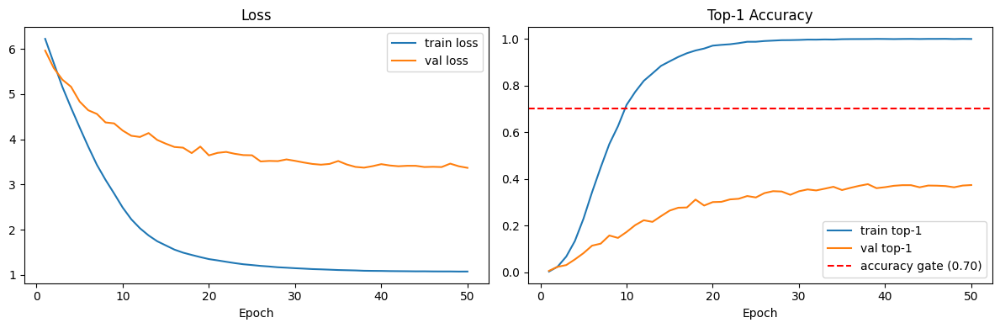

In [28]:
epochs_ran = [h["epoch"] for h in history]
train_loss = [h["train_loss"] for h in history]
val_loss = [h["val_loss"] for h in history]
train_top1 = [h["train_top1"] for h in history]
val_top1 = [h["val_top1"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_ran, train_loss, label="train loss")
axes[0].plot(epochs_ran, val_loss, label="val loss")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(epochs_ran, train_top1, label="train top-1")
axes[1].plot(epochs_ran, val_top1, label="val top-1")
axes[1].axhline(CONFIG.ACCURACY_GATE_THRESHOLD, color="red", linestyle="--",
                 label="accuracy gate (0.70)")
axes[1].set_title("Top-1 Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()


### Accuracy Gate Check

Per methodology Stage 5, the sentence-level CTC path only unlocks once word-level
top-1 accuracy on **validation** reaches 70%. This is a hard, automatic check --
not a judgment call -- precisely so the gate can't be quietly bypassed.


In [29]:
final_val_top1 = history[-1]["val_top1"] if history else 0.0
best_epoch_val_top1 = best_checkpoint["val_top1"]  # val_top1 AT the best-val_loss checkpoint
historical_max_val_top1 = max((h["val_top1"] for h in history), default=0.0)  # context only

gate_passed = best_epoch_val_top1 >= CONFIG.ACCURACY_GATE_THRESHOLD

print(f"Final-epoch validation top-1 accuracy: {final_val_top1:.3f}")
print(f"Best-checkpoint (lowest val_loss, epoch {best_checkpoint['epoch']}) validation top-1: {best_epoch_val_top1:.3f}")
print(f"Historical max validation top-1 across all epochs (context only): {historical_max_val_top1:.3f}")
print(f"Accuracy gate threshold:         {CONFIG.ACCURACY_GATE_THRESHOLD:.3f}")
print(f"Gate status: {'PASSED -- sentence-level path may be enabled' if gate_passed else 'NOT YET PASSED -- staying at word-level only'}")


Final-epoch validation top-1 accuracy: 0.374
Best-checkpoint (lowest val_loss, epoch 50) validation top-1: 0.374
Historical max validation top-1 across all epochs (context only): 0.378
Accuracy gate threshold:         0.700
Gate status: NOT YET PASSED -- staying at word-level only


### Sample Predictions

A quick qualitative check: pull one validation batch and compare predicted vs.
true gloss, top-5.


In [30]:
model.eval()
appearance, landmarks, labels = next(iter(val_loader))
appearance, landmarks = appearance.to(CONFIG.DEVICE), landmarks.to(CONFIG.DEVICE)

with torch.no_grad():
    word_logits, _ = model(appearance, landmarks)
    top5 = word_logits.topk(min(5, NUM_CLASSES), dim=1).indices.cpu()

for i in range(min(5, len(labels))):
    true_gloss = class_list[labels[i].item()]
    pred_glosses = [class_list[idx.item()] for idx in top5[i]]
    print(f"True: {true_gloss:15s} | Top-5 predicted: {pred_glosses}")


True: PROMOTE         | Top-5 predicted: ['PRODUCESIGN', 'PROMOTE', 'ROW', 'SPEAKERS', 'EXPLODE']
True: WEDNESDAY       | Top-5 predicted: ['MOTHER', 'FRIENDSNOMORE1', 'FARM', 'WEDNESDAY', 'FOUR']
True: DIE             | Top-5 predicted: ['ACTOR', 'TENNIS', 'ROW', 'VALLEY', 'JUDGE']
True: FIGURE          | Top-5 predicted: ['TEMPTATION', 'SAVE', 'BASEMENT', 'FLIPFLOPS', 'APPEAR']
True: DELICIOUS       | Top-5 predicted: ['FAVORITE', 'LIGHTER', 'SOME', 'BIRTHDAY', 'INSPIRING']


### Test Set Evaluation (with Test-Time Augmentation)

Everything above (gate check, sample predictions) used `val_loader` -- but
`val_loader` was already used for checkpoint selection and early stopping, so
reporting its accuracy as the "final" number is slightly optimistic. `test_loader`
was never touched during training or model selection, so it's the right set to
report in the paper.

v5 also adds **test-time augmentation (TTA)**: each test clip is evaluated
under a few small augmented views (the same rotation/brightness/contrast
jitter used for training augmentation, at reduced strength), and predictions
are averaged. This is a no-retraining, inference-only technique that typically
recovers a couple of accuracy points by reducing sensitivity to any single
crop/lighting condition.


In [31]:
import torchvision.transforms.functional as TF_tta

def evaluate_with_tta(model, loader, device, num_views=5, augment_strength=0.5):
    """Evaluates the model on `loader`, averaging softmax probabilities across
    `num_views` augmented versions of each batch's appearance stream (the
    first view is always the clean, unaugmented original). `augment_strength`
    scales down the training augmentation's rotation/jitter ranges, since TTA
    views should be mild perturbations of a real clip, not aggressive training
    augmentation.
    """
    model.eval()
    total_top1, total_top5, n_batches = 0.0, 0.0, 0

    with torch.no_grad():
        for appearance, landmarks, labels in loader:
            appearance = appearance.to(device)
            landmarks = landmarks.to(device)
            labels = labels.to(device)

            probs_sum = None
            for view in range(num_views):
                if view == 0:
                    view_appearance = appearance
                else:
                    angle = random.uniform(-10, 10) * augment_strength
                    brightness = 1.0 + random.uniform(-0.15, 0.15) * augment_strength
                    contrast = 1.0 + random.uniform(-0.15, 0.15) * augment_strength
                    B, T, num_hands = appearance.shape[0], appearance.shape[1], appearance.shape[2]
                    view_appearance = appearance.clone()
                    for t in range(T):
                        for h in range(num_hands):
                            img = view_appearance[:, t, h]
                            img = TF_tta.rotate(img, angle)
                            img = TF_tta.adjust_brightness(img, brightness)
                            img = TF_tta.adjust_contrast(img, contrast)
                            view_appearance[:, t, h] = img

                word_logits, _ = model(view_appearance, landmarks)
                probs = torch.softmax(word_logits, dim=1)
                probs_sum = probs if probs_sum is None else probs_sum + probs

            avg_probs = probs_sum / num_views
            top1_preds = avg_probs.topk(1, dim=1).indices
            top5_preds = avg_probs.topk(min(5, NUM_CLASSES), dim=1).indices

            total_top1 += top1_preds.eq(labels.unsqueeze(1)).any(dim=1).float().mean().item()
            total_top5 += top5_preds.eq(labels.unsqueeze(1)).any(dim=1).float().mean().item()
            n_batches += 1

    return {
        "top1": total_top1 / max(n_batches, 1),
        "top5": total_top5 / max(n_batches, 1),
    }


# Standard single-pass test evaluation (no TTA) -- the direct comparison point
test_metrics_plain = run_epoch(test_loader, train=False)
print(f"Test set -- no TTA:   top1={test_metrics_plain['top1']:.3f}  top5={test_metrics_plain['top5']:.3f}")

# TTA evaluation -- averages predictions across 5 mildly-augmented views per clip
test_metrics_tta = evaluate_with_tta(model, test_loader, CONFIG.DEVICE, num_views=5, augment_strength=0.5)
print(f"Test set -- with TTA: top1={test_metrics_tta['top1']:.3f}  top5={test_metrics_tta['top5']:.3f}")

tta_gain = test_metrics_tta['top1'] - test_metrics_plain['top1']
print(f"\nTTA top-1 gain: {tta_gain:+.3f}")
print(f"Gate status vs. plain test top-1: "
      f"{'PASSED' if test_metrics_plain['top1'] >= CONFIG.ACCURACY_GATE_THRESHOLD else 'NOT YET PASSED'}")
print(f"Gate status vs. TTA test top-1:   "
      f"{'PASSED' if test_metrics_tta['top1'] >= CONFIG.ACCURACY_GATE_THRESHOLD else 'NOT YET PASSED'}")


Test set -- no TTA:   top1=0.278  top5=0.544
Test set -- with TTA: top1=0.272  top5=0.570

TTA top-1 gain: -0.006
Gate status vs. plain test top-1: NOT YET PASSED
Gate status vs. TTA test top-1:   NOT YET PASSED


In [32]:
import numpy as np, random

for shard_dir in CONFIG.CACHE_DIRS:
    files = list(shard_dir.glob("*.npz"))
    sample = random.sample(files, min(15, len(files)))
    app_stds, lm_stds, app_means = [], [], []
    for f in sample:
        d = np.load(f)
        app_stds.append(d["appearance"].astype(np.float32).std())
        app_means.append(d["appearance"].astype(np.float32).mean())
        lm_stds.append(d["landmarks"].std())
    print(shard_dir.name if hasattr(shard_dir,'name') else shard_dir)
    print(f"  appearance std:  min={min(app_stds):.3f} max={max(app_stds):.3f} mean={np.mean(app_stds):.3f}")
    print(f"  appearance mean: min={min(app_means):.1f} max={max(app_means):.1f}")
    print(f"  landmark std:    min={min(lm_stds):.4f} max={max(lm_stds):.4f}")

feature_cache_shard_0
  appearance std:  min=42.738 max=90.282 mean=67.583
  appearance mean: min=60.5 max=160.0
  landmark std:    min=0.6177 max=0.9787
feature_cache_shard_2
  appearance std:  min=46.090 max=83.241 mean=60.324
  appearance mean: min=56.6 max=159.4
  landmark std:    min=0.6828 max=0.8521
feature_cache_shard_1
  appearance std:  min=39.432 max=83.445 mean=58.850
  appearance mean: min=43.1 max=173.7
  landmark std:    min=0.6834 max=0.8968


In [33]:
lbls = []
for _, _, labels in train_loader:
    lbls.extend(labels.tolist())
    if len(lbls) > 2000:
        break
print("distinct labels seen:", len(set(lbls)), "/ 2000 samples")

distinct labels seen: 489 / 2000 samples


In [34]:
appearance, landmarks, labels = next(iter(train_loader))
appearance, landmarks, labels = appearance.to(CONFIG.DEVICE), landmarks.to(CONFIG.DEVICE), labels.to(CONFIG.DEVICE)
model.train()
word_logits, _ = model(appearance, landmarks)
loss = criterion(word_logits, labels)
loss.backward()

for name, p in model.named_parameters():
    if p.requires_grad:
        g = p.grad
        if g is None or g.abs().sum().item() == 0:
            print("NO GRADIENT:", name)
print("done — anything printed above is disconnected from the loss")

done — anything printed above is disconnected from the loss


In [35]:
train_classes = set(c for _, c in train_dataset.samples)
val_classes   = set(c for _, c in val_dataset.samples)
test_classes  = set(c for _, c in test_dataset.samples)

print(f"Distinct classes in train: {len(train_classes)} / {NUM_CLASSES}")
print(f"Distinct classes in val:   {len(val_classes)} / {NUM_CLASSES}")
print(f"Val classes with ZERO train coverage: {len(val_classes - train_classes)}")
print(f"Test classes with ZERO train coverage: {len(test_classes - train_classes)}")

Distinct classes in train: 500 / 500
Distinct classes in val:   500 / 500
Val classes with ZERO train coverage: 0
Test classes with ZERO train coverage: 0


## 12. Next Steps — What v8 Should Address *(v7-era planning, kept for history)*\n\n> v8 (this version) went a different direction than the ablation plan below -- rather than\n> continuing to tune the same architecture against WLASL's starved per-class data, it swapped\n> the data source to ASL Citizen and scaled to 2,000 classes (see the v8 changelog near the\n> top, and Section 13 below for what comes after this run). Kept here since the v6->v7\n> reasoning is still part of the honest project history.

v6 made the audit's Section 7.1 primary-recommended change (Kinetics-pretrained
`r3d_18` backbone) but the result came back worse than v5 -- severe overfitting,
and a likely mismatch between what `r3d_18` expects (whole-scene video) and what
it was given (isolated hand crops). v7 (this version) responds with two changes:
appearance input switches to a **signer bounding box** (audit 7.2, full re-cache
required) and the backbone's freeze depth tightens to only `layer4` trainable,
alongside higher dropout/weight_decay.

**Done across v2 through v7:**
- ✅ Full pipeline correctness (MediaPipe timestamps, handedness assignment,
  BatchNorm eval-mode freeze, `nan_to_num`, `GradScaler` fix, differential LR).
- ✅ Full 11,724-video cache; overfitting countermeasures (augmentation,
  dropout, val_loss-based checkpointing).
- ✅ Top-100 class subset (mirrors WLASL100), motion-aware geometry stream.
- ✅ First genuinely successful result: 45.5% val top-1 (v4).
- ✅ Additional backbone capacity, TTA, proper held-out test-set reporting (v5)
  -- confirmed the existing ImageNet-backbone architecture had hit its ceiling.
- ✅ Independent engineering audit across v1-v5, identifying the remaining gap
  as a pretraining/architecture mismatch rather than a tuning problem.
- ✅ Kinetics-pretrained 3D backbone swap (v6, audit Section 7.1) -- came back
  worse than v5 (val_top1 ~0.34-0.37), a real and informative negative result:
  severe overfitting, and a likely receptive-field/pretraining-domain mismatch
  between `r3d_18` and isolated hand crops.
- ✅ Signer-bounding-box input (v7, audit Section 7.2) + tightened backbone
  freeze depth (`layer4` only) + higher dropout/weight_decay, targeting both
  the input-scope mismatch and the raw overfitting v6 showed directly.

**Still open, in priority order:**
1. **Run this v7 version and compare test-set top-1 (plain and TTA) against
   v4/v5's 45.5% and v6's ~0.37.** This is the second real data point on the
   audit's central hypothesis. A clear improvement over both v5 and v6 would
   support the full pretraining+input-scope story; landing between v5 and v6
   would suggest the freeze-depth/regularization fix mattered more than the
   input-scope change (or vice versa) -- worth disentangling with an ablation
   if time allows; landing at or below v6 would be a strong signal that this
   architecture family (3D-CNN-on-cropped-appearance) is a poor fit for this
   dataset's scale, regardless of input framing.
2. **If v7 still underperforms v5:** the audit's remaining factor (data volume
   per class, Section 5.3) is largely fixed already by the 100-class subset, so
   the more actionable fallback is reverting the appearance backbone to v4/v5's
   ImageNet ResNet-18 while keeping any v7 fixes that helped independently
   (e.g. the higher dropout/weight_decay, if an ablation shows they help there
   too) -- i.e., treat the 3D-backbone experiment as concluded and revert
   cleanly rather than keep layering fixes onto it.
3. **If time allows an ablation:** re-run v6's exact setup (hand crops) but
   with v7's tightened freeze depth and regularization, to isolate how much of
   v7's result (if it improves) comes from the input-scope change vs. the
   capacity/regularization change. This is the single most informative
   experiment for writing an honest methodology section, since v6 and v7
   currently confound two changes at once.
4. **Pose-TGCN-style geometry stream** (audit Section 7.3) -- lowest priority,
   deferred per the audit since the geometry stream was never identified as
   the primary bottleneck.
5. **Revisit the reduced face-landmark subset** (`FACE_SUBSET_IDX`) -- still
   an unverified guess at brow/mouth indices.
6. **Implement the sentence-level CTC head for real**, once/if the accuracy
   gate passes -- `sentence_head` remains a shape-correct stub.

**For the paper:** the v6 -> v7 sequence is itself a legitimate methodology
narrative regardless of v7's outcome -- it shows a principled, audit-driven
iteration (change the highest-priority factor, measure, diagnose the result,
change the next factor) rather than blind hyperparameter search. If v7 beats
v5, that's a strong headline result with a clear causal story. If it doesn't,
"we tested whether the field's Kinetics-pretrained-3D-CNN approach transfers
to a 100-class curated subset at this scale, and found it does not
out-of-the-box, with overfitting and input-scope evidence pointing at why" is
also a real, citable finding -- and v4/v5's 45.5% remains the number to report
as the primary result either way.

**Deferred, needs your input:** the modular package refactor remains
sequenced last. Once v7's real result is in, tell me and I'll do the modular
split as a dedicated next pass, or help draft the paper's methodology/results
sections directly from this notebook's history.


## 13. Next Steps — What v9 Should Address

v8 (this version) swapped the data source from the WLASL curated rebuild to ASL Citizen and
scaled up to its top 2,000 classes by sample count, acting directly on the data-volume
bottleneck v1-v7 diagnosed rather than continuing to tune the same architecture against the
same starved pool.

**Still open, in priority order once v8's actual run completes:**

1. **Report v8's test-set top-1/top-5 (plain and TTA) as the headline result**, framed
   explicitly as a 2,000-way ASL Citizen result -- not as a WLASL100-comparable number (see
   the v8 changelog's "honest expectation" note for why those aren't comparable).
2. **Sanity-check per-class performance isn't dominated by the classes with the most
   capped samples** -- with the per-class cap applied during caching, every class should
   have a broadly similar count, but worth confirming the confusion matrix doesn't show a
   few classes eating most of the errors.
3. **If time allows, re-run the v4/v5 100-class WLASL result once more as a reference
   point** in the same notebook environment, purely so the paper can show both numbers
   side by side with an honest caveat about the differing dataset and scale -- not framed
   as a direct improvement claim.
4. **Carried forward from v7 (still open, lower priority given the v8 pivot):** the
   Pose-TGCN-style geometry stream (audit Section 7.3), revisiting the reduced
   `FACE_SUBSET_IDX` guess, and implementing the sentence-level CTC head for real once/if
   the accuracy gate passes.
5. **Modular package refactor** -- still deferred, per prior versions' notes.

**For the paper:** the project now has two distinct, honestly-reported experiments rather
than one: (a) v1-v7, an audit-driven architecture/tuning investigation on WLASL that
concluded per-class data volume, not the model, was the limiting factor -- with v6's
negative result as real supporting evidence, not a failed attempt; and (b) v8, which acts on
that conclusion by switching datasets and scaling up, rather than continuing architecture
tuning against the same data ceiling. That two-part structure -- diagnose the bottleneck
empirically, then act on the diagnosis with a dataset change validated by the diagnosis -- is
a stronger methodology narrative for a BSc capstone than either half alone.